# ML Lab: Normalization, Image Processing and Building an ANN with TensorFlow

**Name:** Umer Mehmood
**Course:** Machine Learning
**Tools:** Python, TensorFlow 2.x (Keras), NumPy, Pillow, Matplotlib, scikit-learn

### Learning Objectives
1. Explain what normalization is and why it matters for machine learning.
2. Apply min-max scaling and standardization (z-score) to numerical data.
3. Load, resize, and preprocess images using Pillow, NumPy, and TensorFlow.
4. Build, compile, train, and evaluate an ANN in TensorFlow/Keras.
5. Measure how normalization changes model performance.

## Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import time
import random
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from PIL import Image, ImageOps, ImageDraw

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

tf.keras.utils.set_random_seed(42)

TensorFlow: 2.21.0
NumPy: 2.5.3


**Sample images.** The lab asks for `my_image.jpg`, `my_clothing.jpg` and `my_pet.jpg`. The cell below creates them only if they are missing:
a coffee cup photo and a cat photo from scikit-image's built-in sample images, and a simple T-shirt drawn on a white background.
Upload your own files with the same names to use them instead.

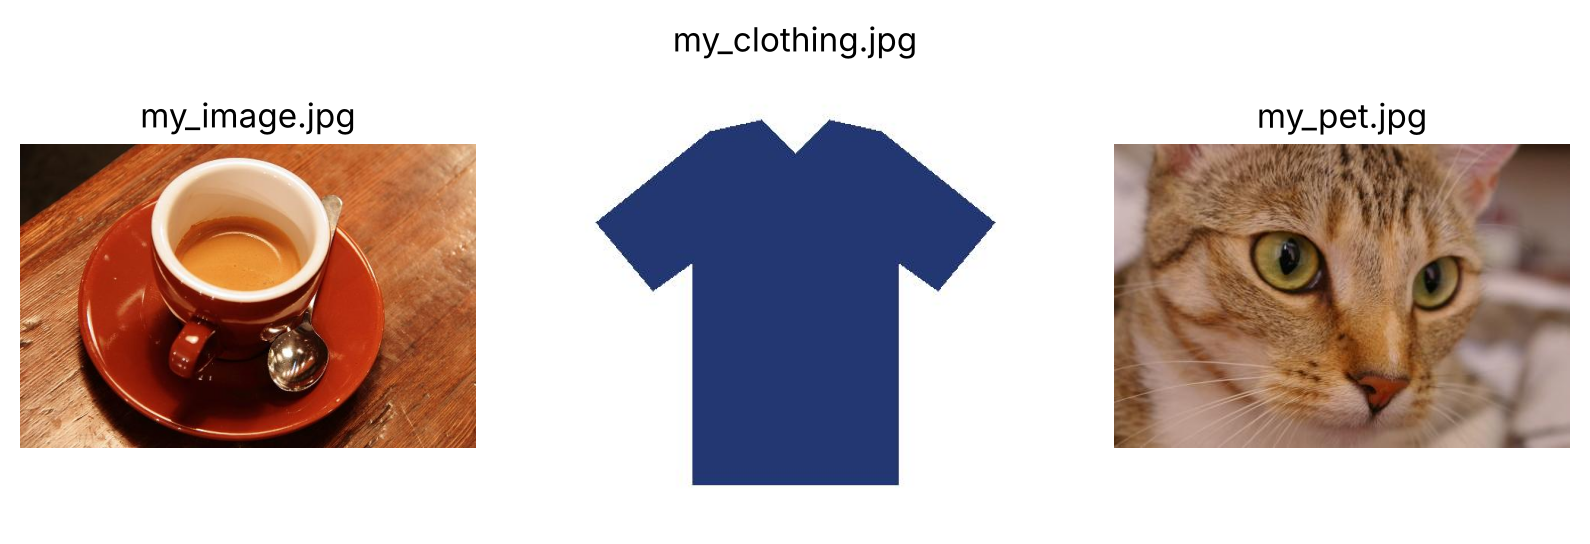

In [2]:
from skimage import data as skdata

if not os.path.exists("my_image.jpg"):
    Image.fromarray(skdata.coffee()).save("my_image.jpg")

if not os.path.exists("my_pet.jpg"):
    Image.fromarray(skdata.chelsea()).save("my_pet.jpg")

if not os.path.exists("my_clothing.jpg"):
    shirt = Image.new("RGB", (400, 400), "white")
    draw = ImageDraw.Draw(shirt)
    draw.polygon([(125, 55), (170, 45), (200, 75), (230, 45), (275, 55),
                  (375, 135), (325, 195), (290, 170), (290, 365),
                  (110, 365), (110, 170), (75, 195), (25, 135)],
                 fill=(35, 55, 115))
    shirt.save("my_clothing.jpg")

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for a, f in zip(ax, ["my_image.jpg", "my_clothing.jpg", "my_pet.jpg"]):
    a.imshow(Image.open(f)); a.set_title(f); a.axis("off")
plt.show()

## Part 1: What Is Normalization?

### 1.1 Concept
**Normalization** rescales input features so they sit in a similar numeric range. Raw data often mixes very different scales,
e.g. *age* (18 to 25) and *annual income* (20,000 to 200,000). Without rescaling, the large-valued feature dominates learning.

Why it matters: faster gradient descent convergence, stable updates (no huge gradients), no feature dominating just because of its units,
and better behaviour of saturating activations like sigmoid and tanh.

### 1.2 Two Common Methods

| Method | Formula | Result range | Use when |
|---|---|---|---|
| Min-Max Scaling | x' = (x - min) / (max - min) | 0 to 1 | Known bounds, e.g. image pixels |
| Standardization (Z-score) | x' = (x - mean) / std | Mean 0, std 1 | Data roughly bell-shaped, has outliers |

### 1.3 Hands-on

In [3]:
# [age, income]
data = np.array([[18, 25000],
                 [21, 48000],
                 [23, 90000],
                 [25, 150000]], dtype=float)

# Min-max scaling
min_vals = data.min(axis=0)
max_vals = data.max(axis=0)
minmax = (data - min_vals) / (max_vals - min_vals)

# Standardization
mean = data.mean(axis=0)
std = data.std(axis=0)
zscore = (data - mean) / std

print("Original:\n", data)
print("Min-max:\n", np.round(minmax, 3))
print("Z-score:\n", np.round(zscore, 3))

Original:
 [[1.8e+01 2.5e+04]
 [2.1e+01 4.8e+04]
 [2.3e+01 9.0e+04]
 [2.5e+01 1.5e+05]]
Min-max:
 [[0.    0.   ]
 [0.429 0.184]
 [0.714 0.52 ]
 [1.    1.   ]]
Z-score:
 [[-1.45  -1.12 ]
 [-0.29  -0.636]
 [ 0.483  0.247]
 [ 1.257  1.51 ]]


The same thing using scikit-learn:

In [4]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

print(MinMaxScaler().fit_transform(data))
print(StandardScaler().fit_transform(data))

[[0.         0.        ]
 [0.42857143 0.184     ]
 [0.71428571 0.52      ]
 [1.         1.        ]]
[[-1.45010473 -1.12032357]
 [-0.29002095 -0.63642794]
 [ 0.48336824  0.24720755]
 [ 1.25675744  1.50954397]]


### 1.4 Important Rule: Avoid Data Leakage
Scaling statistics (min, max, mean, std) are computed from the **training set only** and then applied to the validation and test sets.
The lab snippet uses `X_train` / `X_test`, so here it is run on a small synthetic dataset split into train and test.

In [5]:
from sklearn.model_selection import train_test_split

rng = np.random.default_rng(42)
X = np.column_stack([rng.integers(18, 26, 200),
                     rng.normal(80000, 35000, 200)]).astype(float)
X_train, X_test = train_test_split(X, test_size=0.25, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn from train
X_test_scaled = scaler.transform(X_test)         # only apply to test

print("Learned from train -> mean:", np.round(scaler.mean_, 2), " std:", np.round(scaler.scale_, 2))
print("Train scaled mean:", np.round(X_train_scaled.mean(axis=0), 3), " std:", np.round(X_train_scaled.std(axis=0), 3))
print("Test  scaled mean:", np.round(X_test_scaled.mean(axis=0), 3), " std:", np.round(X_test_scaled.std(axis=0), 3))

Learned from train -> mean: [2.16600e+01 7.90714e+04]  std: [2.190000e+00 3.484129e+04]
Train scaled mean: [-0.  0.]  std: [1. 1.]
Test  scaled mean: [-0.155 -0.021]  std: [1.028 0.986]


### Task 1 (Part 1)
**1.1 Min, max, mean and standard deviation of each column before and after scaling**

In [6]:
def describe(title, arr):
    df = pd.DataFrame({"min": arr.min(axis=0),
                       "max": arr.max(axis=0),
                       "mean": arr.mean(axis=0),
                       "std": arr.std(axis=0)},
                      index=["age", "income"])
    print(title)
    display(df.round(3))

describe("Original data", data)
describe("After min-max scaling", minmax)
describe("After standardization (z-score)", zscore)

Original data


,min,max,mean,std
age,18.0,25.0,21.75,2.586
income,25000.0,150000.0,78250.00,47530.911


After min-max scaling


,min,max,mean,std
age,0.0,1.0,0.536,0.369
income,0.0,1.0,0.426,0.380


After standardization (z-score)


,min,max,mean,std
age,-1.45,1.257,-0.0,1.0
income,-1.12,1.510,0.0,1.0


**1.2 Which method for a dataset with extreme outliers, and why?**

**Answer:**

I would choose **standardization (z-score)**. Min-max scaling depends only on the minimum and maximum, so a single extreme value becomes 0 or 1 and squeezes every normal point into a tiny range. For example, if one income in the table were 5,000,000, all the other incomes would end up below about 0.03 after min-max scaling. Z-score uses the mean and standard deviation of all points and has no fixed bounds, so the bulk of the data keeps a usable spread even though the outlier still shifts the statistics a little. For very heavy outliers, `RobustScaler` (median and IQR) is even better because the median and IQR are hardly affected by extreme values.

**1.3 Why is fitting a scaler on the test set a mistake?**

**Answer:**

The test set is meant to stand in for new, unseen data. If the scaler is fitted on it, the model's preprocessing has already "seen" the test distribution (its min, max, mean and std). That is data leakage, and it makes the test score optimistic compared with real deployment, where only the training statistics exist. It also means the same raw value would be scaled differently for training and testing, even though the model learned the training scale. Section 1.4 shows the honest version: with the scaler fitted on train only, the test set's scaled mean comes out at about -0.155 and its std at 1.03, not exactly 0 and 1. That small mismatch is real information about how new data differs, and fitting on the test set would hide it.

## Part 2: Image Processing (Resize, Rescale, Inspect)

Neural networks need inputs of a **fixed size**. A dense ANN expecting 28x28 images cannot accept a 640x480 photo, so images are resized first.
Pixel values are also rescaled, which is normalization applied to images.

### 2.1 Images as Arrays
Grayscale: shape `(height, width)`. Color (RGB): shape `(height, width, 3)`. Pixel values are integers from 0 (black) to 255 (white).

### 2.2 Load and Resize an Image

Original size (W x H): (600, 400)
Mode: RGB
As array: (400, 600, 3) uint8
New size: (28, 28)


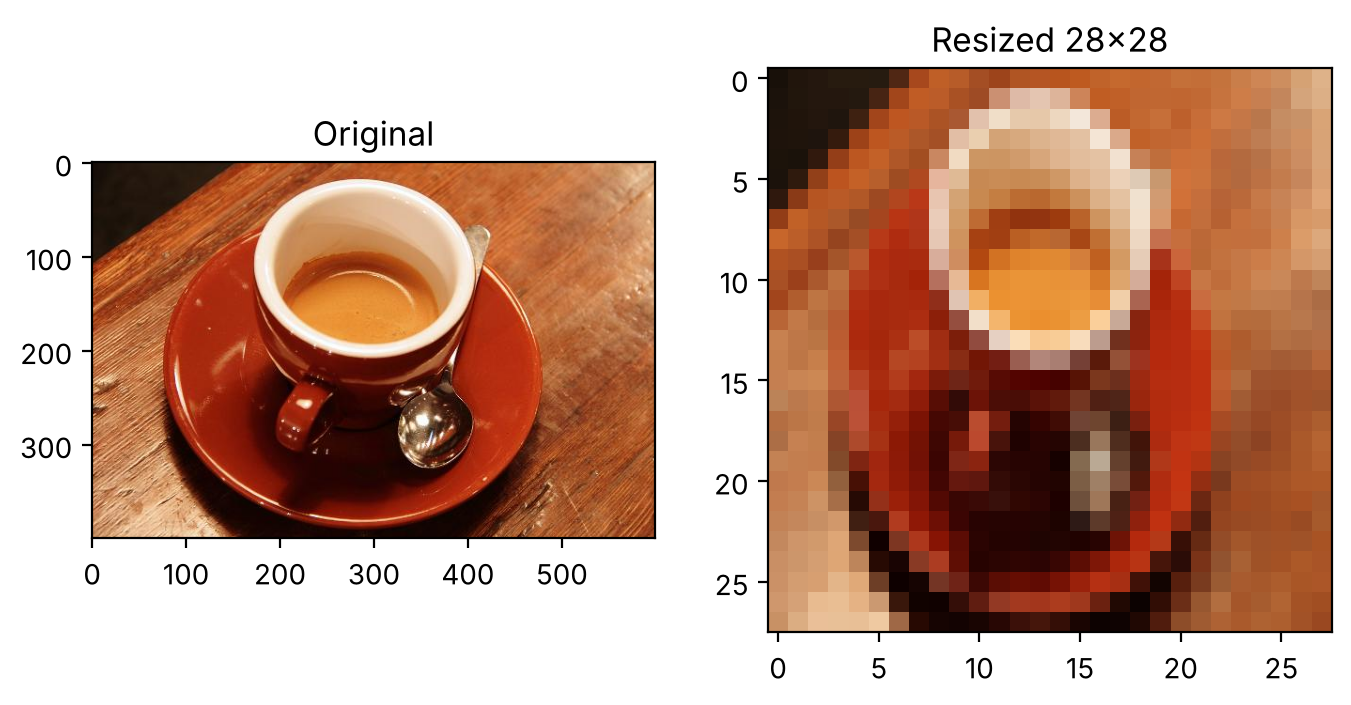

In [7]:
img = Image.open("my_image.jpg")
print("Original size (W x H):", img.size)
print("Mode:", img.mode)
print("As array:", np.array(img).shape, np.array(img).dtype)

# Resize to 28x28
img_resized = img.resize((28, 28))
print("New size:", img_resized.size)

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(img); ax[0].set_title("Original")
ax[1].imshow(img_resized); ax[1].set_title("Resized 28x28")
plt.show()

### 2.3 Convert to Grayscale and Normalize

Shape: (28, 28)
Pixel range before: 2 to 233
Pixel range after: 0.007843138 to 0.9137255


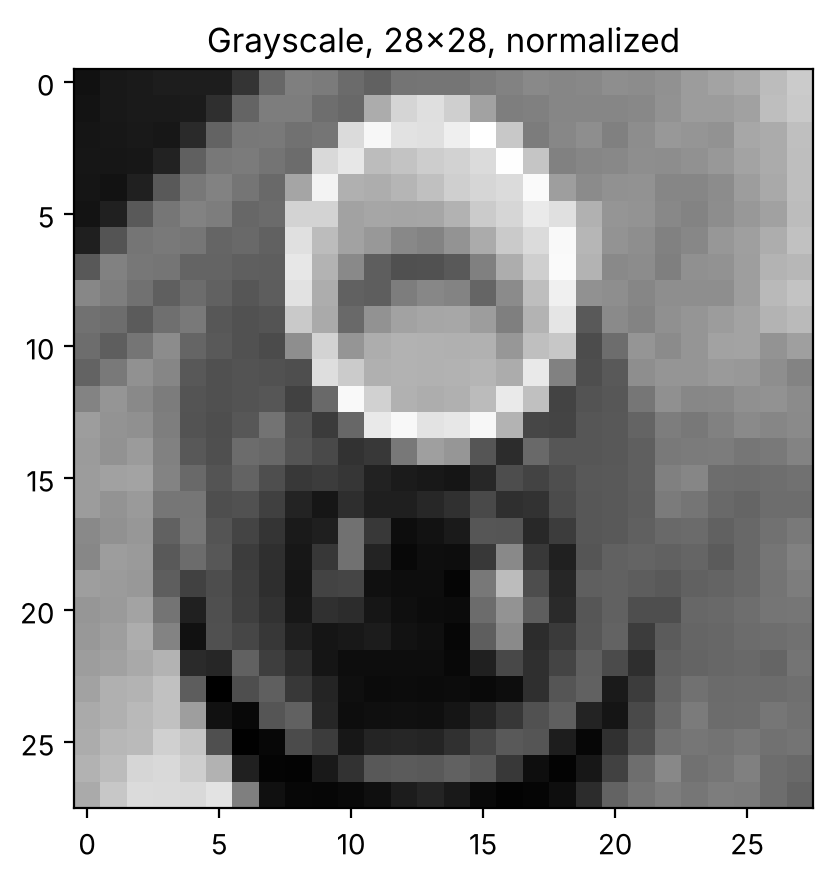

In [8]:
gray = img.convert("L").resize((28, 28))   # "L" = grayscale
arr = np.array(gray)

print("Shape:", arr.shape)
print("Pixel range before:", arr.min(), "to", arr.max())

arr_norm = arr.astype("float32") / 255.0   # min-max scaling to [0, 1]
print("Pixel range after:", arr_norm.min(), "to", arr_norm.max())

plt.imshow(arr_norm, cmap="gray")
plt.title("Grayscale, 28x28, normalized")
plt.show()

### 2.4 Resizing with TensorFlow
TensorFlow can resize whole batches, which is useful inside training pipelines.

(64, 64, 3)


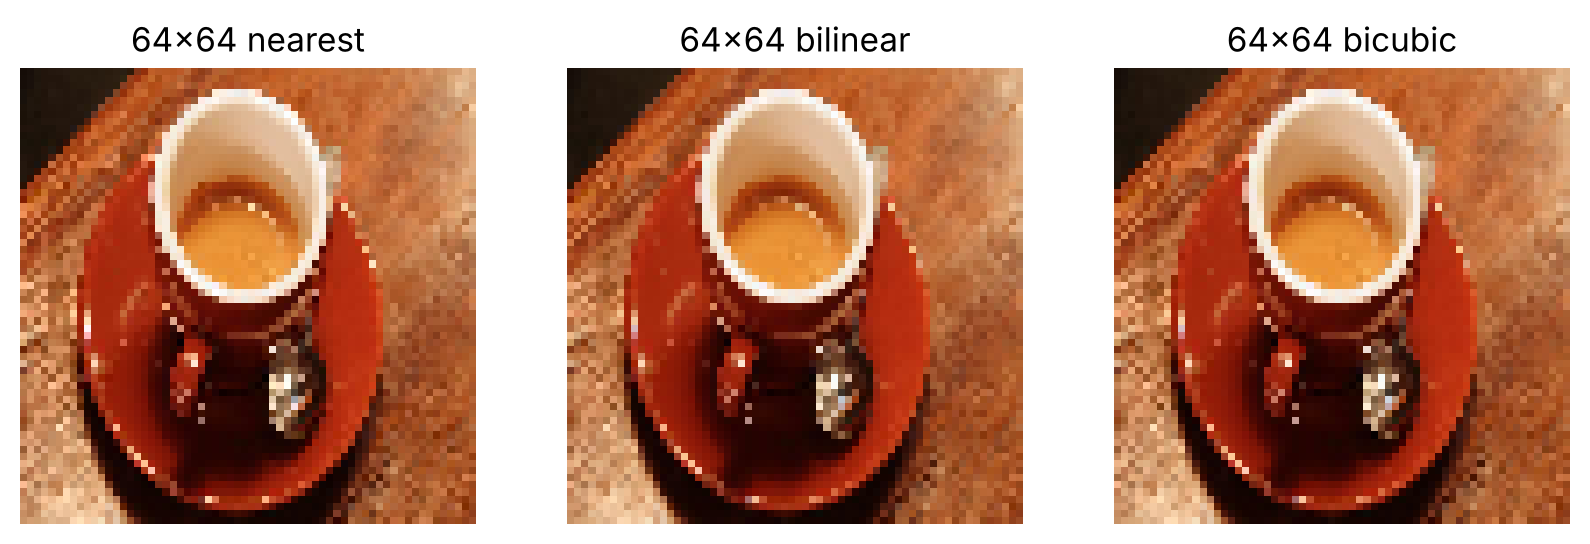

In [9]:
img_tf = tf.keras.utils.img_to_array(img)        # shape (H, W, 3)
resized = tf.image.resize(img_tf, (64, 64))     # bilinear by default
print(resized.shape)

# Compare interpolation methods
nearest = tf.image.resize(img_tf, (64, 64), method="nearest")
bilinear = tf.image.resize(img_tf, (64, 64), method="bilinear")
bicubic = tf.image.resize(img_tf, (64, 64), method="bicubic")

def show(t):
    # float tensor in 0..255 -> displayable 0..1 (bicubic can overshoot slightly, so clip)
    return np.clip(np.array(t) / 255.0, 0, 1)

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for a, (name, t) in zip(ax, [("nearest", nearest), ("bilinear", bilinear), ("bicubic", bicubic)]):
    a.imshow(show(t), interpolation="nearest"); a.set_title(f"64x64 {name}"); a.axis("off")
plt.show()

**Interpolation methods in short:** *nearest neighbor* is fastest with blocky results, *bilinear* is smooth and a good default,
*bicubic* is smoother and sharper but slower.

### 2.5 Other Useful Operations

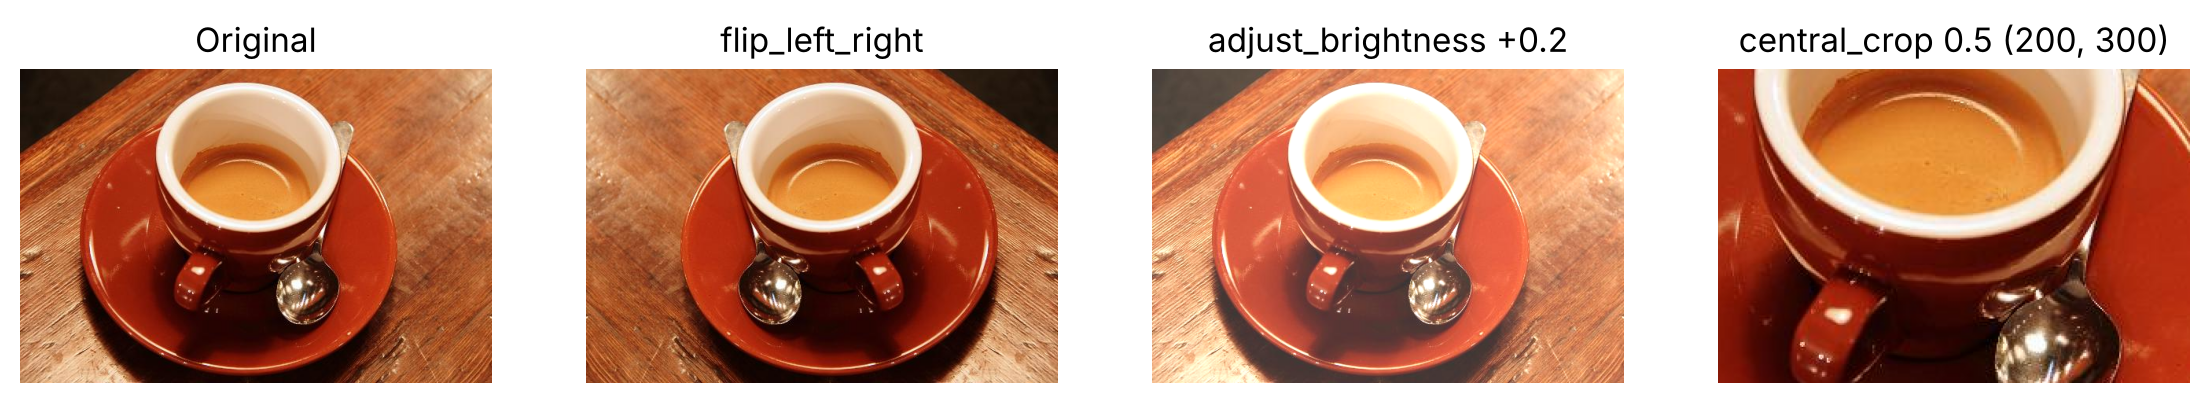

In [10]:
flipped = tf.image.flip_left_right(img_tf)
bright = tf.image.adjust_brightness(img_tf / 255.0, delta=0.2)
cropped = tf.image.central_crop(img_tf, central_fraction=0.5)

fig, ax = plt.subplots(1, 4, figsize=(14, 3.5))
ax[0].imshow(show(img_tf)); ax[0].set_title("Original")
ax[1].imshow(show(flipped)); ax[1].set_title("flip_left_right")
ax[2].imshow(np.clip(np.array(bright), 0, 1)); ax[2].set_title("adjust_brightness +0.2")
ax[3].imshow(show(cropped)); ax[3].set_title(f"central_crop 0.5 {tuple(cropped.shape[:2])}")
for a in ax: a.axis("off")
plt.show()

### Task 2 (Part 2)
**2.1 Resize to 8x8, 28x28 and 128x128 and display side by side**

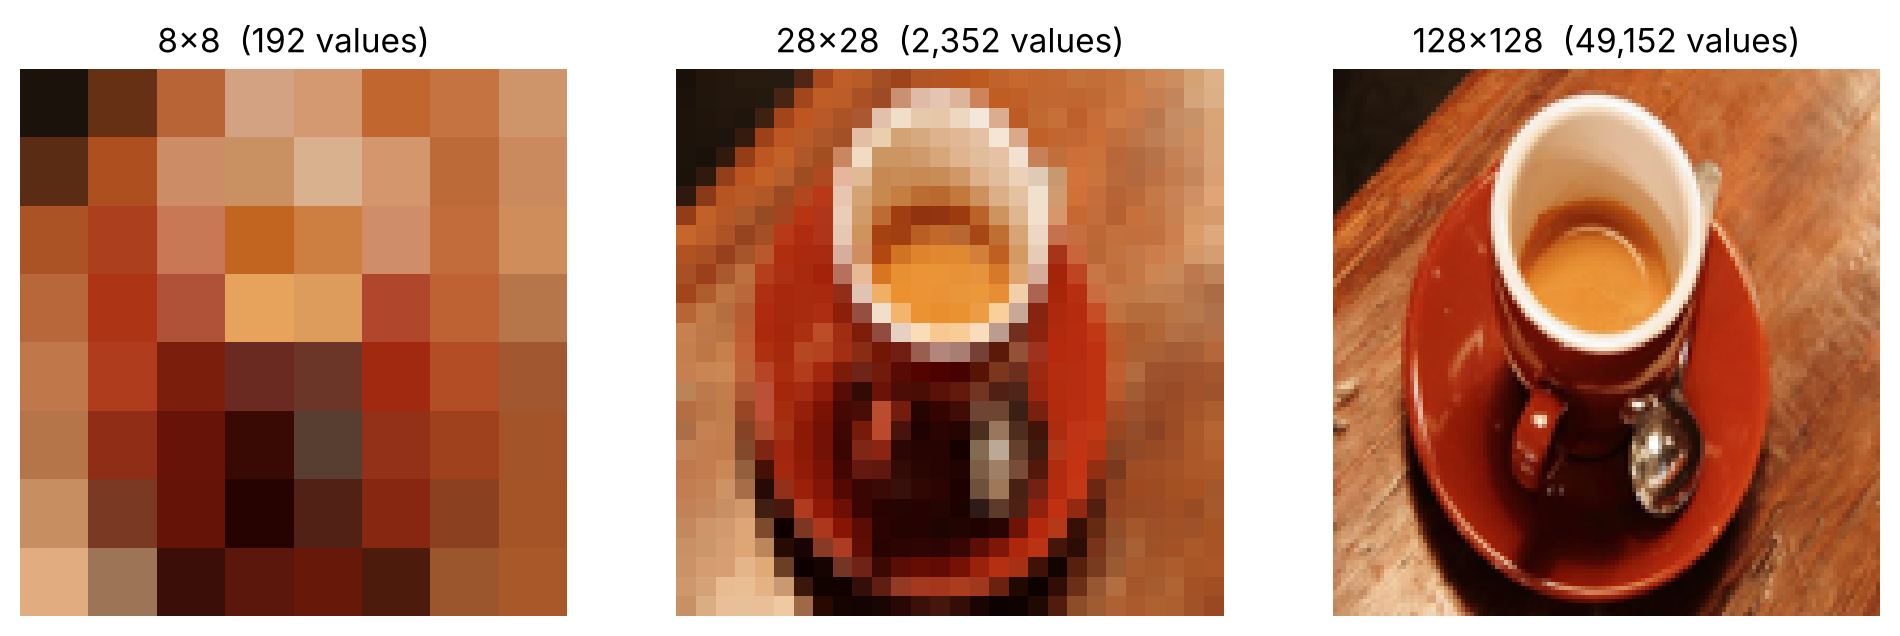

In [11]:
sizes = [8, 28, 128]
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, s in zip(ax, sizes):
    a.imshow(img.resize((s, s)), interpolation="nearest")
    a.set_title(f"{s}x{s}  ({s*s*3:,} values)")
    a.axis("off")
plt.show()

**Answer:**

At **8x8** there are only 64 pixels (192 values), so the photo becomes a grid of orange and brown blocks. You can no longer tell it is a cup: the rim, handle, spoon and wood grain are all gone. At **28x28** the cup and saucer are recognisable but fine details like the spoon and the wood texture are lost. At **128x128** almost all the detail is still there. Smaller images give fewer inputs (192 vs 49,152 values) and faster models, but they throw away information the model might need.

**2.2 Compare nearest, bilinear and bicubic interpolation on a 32x32 version**

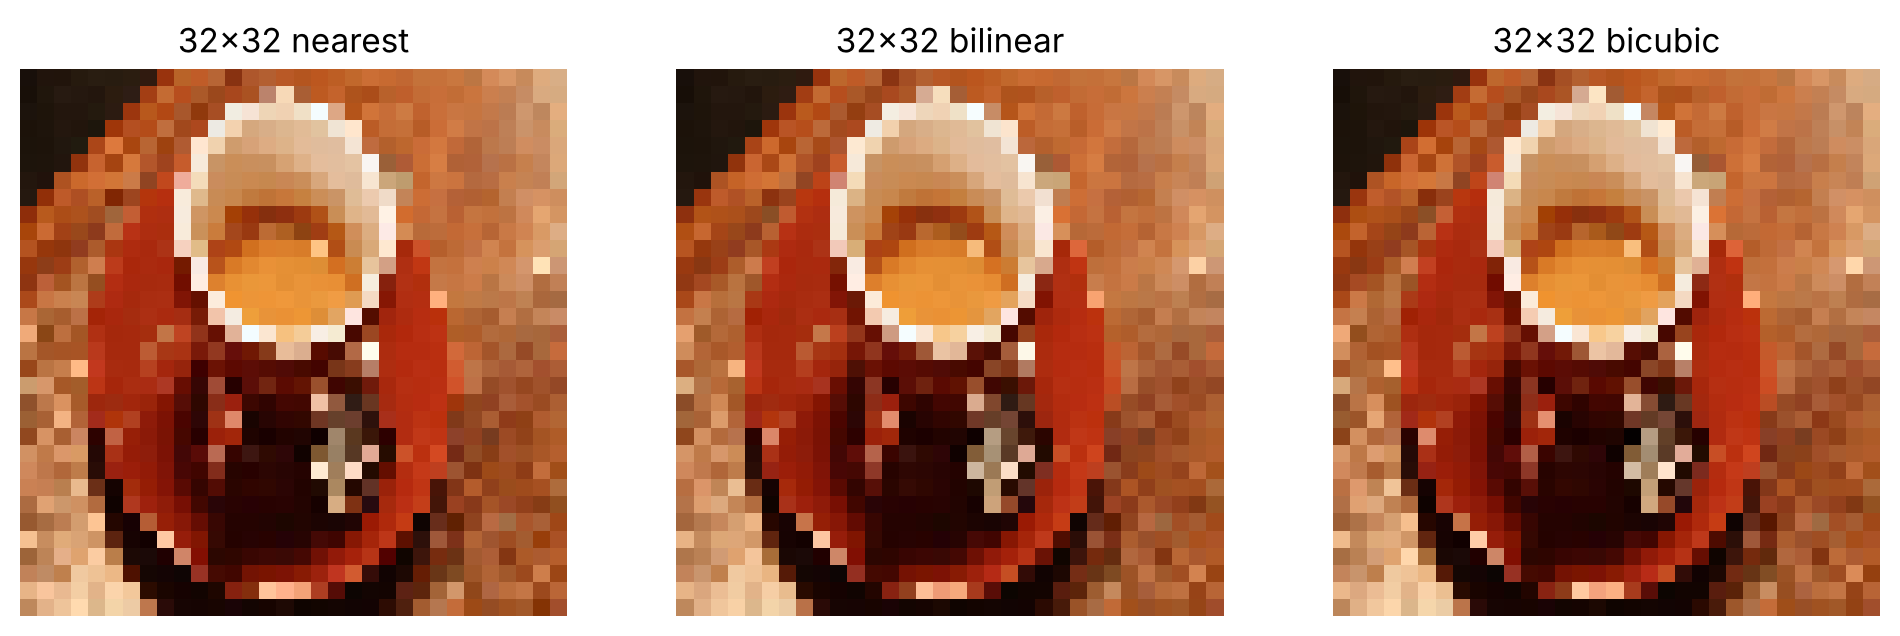

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(12, 4))
for a, m in zip(ax, ["nearest", "bilinear", "bicubic"]):
    small = tf.image.resize(img_tf, (32, 32), method=m)
    a.imshow(show(small), interpolation="nearest")
    a.set_title(f"32x32 {m}")
    a.axis("off")
plt.show()

**Answer:**

This is heavy downscaling (600x400 to 32x32). **Nearest** copies one source pixel per output pixel, so the result is jagged and noisy: the cup rim breaks up and the wood grain turns into speckles (aliasing). **Bilinear** and **bicubic** look smoother. At this size they look very similar, with bicubic keeping slightly crisper edges on the rim and handle because it blends a 4x4 neighbourhood with cubic weights, while bilinear uses 2x2. I'd pick **bicubic** for quality (bilinear is close and cheaper). Note that `tf.image.resize` uses `antialias=False` by default, so for heavy downscaling `antialias=True` gives a cleaner result with any method.

**2.3 Grayscale, normalize to [0, 1], print shape and min/max**

Shape: (400, 600)
dtype: float32
Min: 0.003921569  Max: 1.0


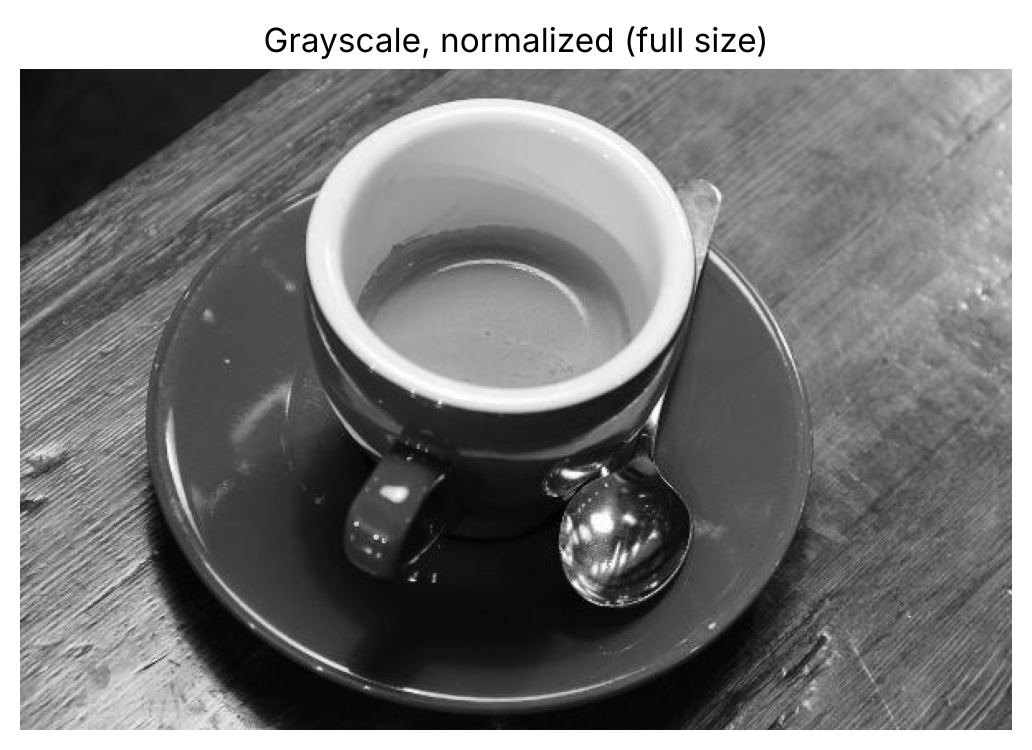

In [13]:
g = np.array(img.convert("L")).astype("float32") / 255.0
print("Shape:", g.shape)
print("dtype:", g.dtype)
print("Min:", g.min(), " Max:", g.max())
plt.imshow(g, cmap="gray"); plt.title("Grayscale, normalized (full size)"); plt.axis("off")
plt.show()

**2.4 Challenge: `preprocess(path, size)`**

my_image.jpg     shape=(28, 28) dtype=float32 min=0.008 max=0.914
my_clothing.jpg  shape=(28, 28) dtype=float32 min=0.161 max=1.000
my_pet.jpg       shape=(28, 28) dtype=float32 min=0.094 max=0.757


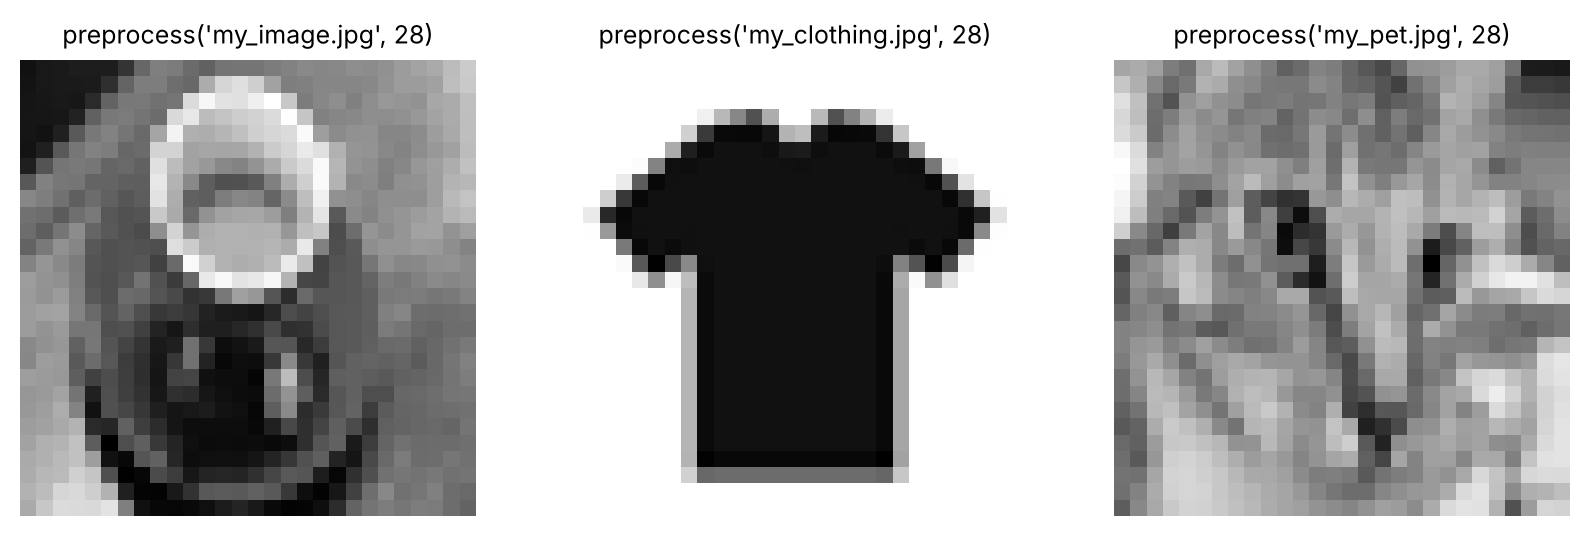

In [14]:
def preprocess(path, size):
    """Load an image, convert to grayscale, resize, normalize to [0, 1].
    Returns a (size, size) float32 array."""
    im = Image.open(path).convert("L").resize((size, size))
    return np.asarray(im, dtype="float32") / 255.0

fig, ax = plt.subplots(1, 3, figsize=(10, 3.5))
for a, f in zip(ax, ["my_image.jpg", "my_clothing.jpg", "my_pet.jpg"]):
    out = preprocess(f, 28)
    print(f"{f:16s} shape={out.shape} dtype={out.dtype} min={out.min():.3f} max={out.max():.3f}")
    a.imshow(out, cmap="gray"); a.set_title(f"preprocess('{f}', 28)", fontsize=9); a.axis("off")
plt.show()

## Part 3: Building an ANN with TensorFlow

Classifier for **Fashion-MNIST**: 70,000 grayscale 28x28 images of clothing in 10 classes.

### 3.1 What Is an ANN?
Each neuron computes a weighted sum of its inputs plus a bias and passes it through an activation function:
`output = activation(w1·x1 + w2·x2 + ... + b)`. A feed-forward ANN has an input layer (784 pixels), hidden layers, and an output layer (10 class scores).
Training repeats: forward pass, compute loss, backpropagate gradients, update weights with an optimizer.

### 3.2 Step 1: Load the Data

Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)
Pixel range: 0 to 255


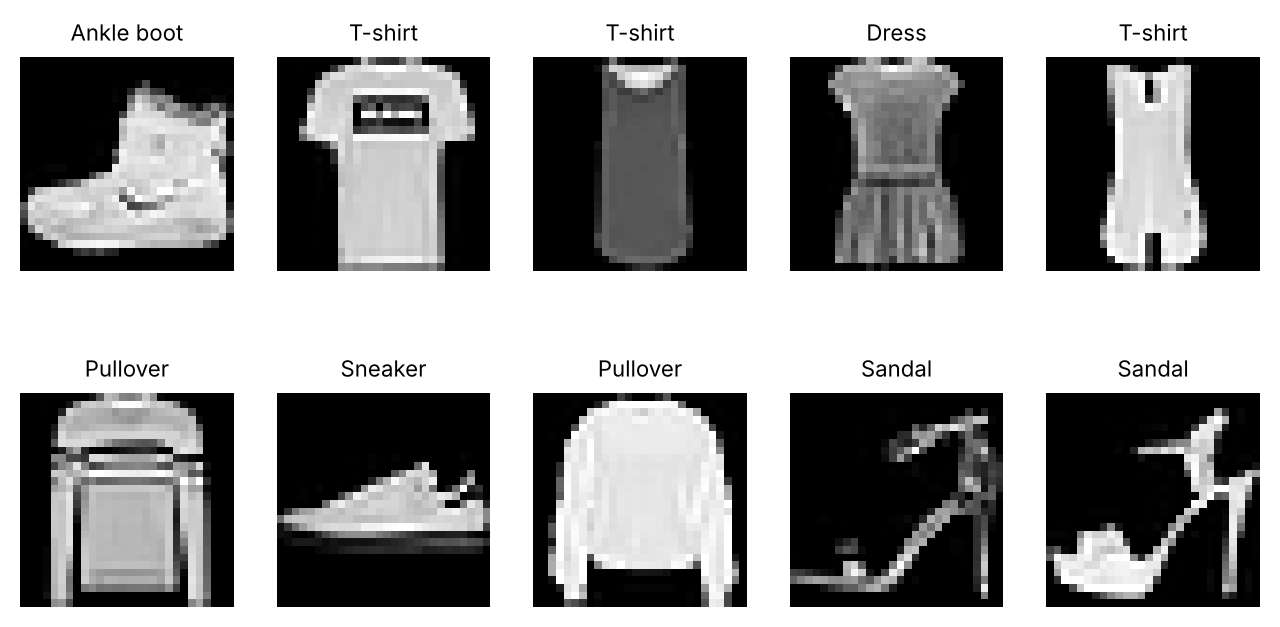

In [15]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

print("Train:", x_train.shape, y_train.shape)   # (60000, 28, 28) (60000,)
print("Test: ", x_test.shape, y_test.shape)     # (10000, 28, 28) (10000,)
print("Pixel range:", x_train.min(), "to", x_train.max())

plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]], fontsize=8)
    plt.axis("off")
plt.show()

### 3.3 Step 2: Normalize the Data
A raw copy is kept for the normalization experiment in Task 3.2.

In [16]:
x_train_raw, x_test_raw = x_train.copy(), x_test.copy()   # 0..255, used in Task 3.2

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
print("After normalization:", x_train.min(), "to", x_train.max(), x_train.dtype)

After normalization: 0.0 to 1.0 float32


### 3.4 Step 3: Build the Model

In [17]:
tf.keras.utils.set_random_seed(42)

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),                        # 28x28 -> 784
    tf.keras.layers.Dense(128, activation="relu"),    # hidden layer 1
    tf.keras.layers.Dense(64, activation="relu"),     # hidden layer 2
    tf.keras.layers.Dense(10, activation="softmax")   # output: 10 class probabilities
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

| Component | Choice | Why |
|---|---|---|
| Flatten | 28x28 to 784 | Dense layers need a 1D vector |
| ReLU | max(0, x) | Fast, avoids vanishing gradients in hidden layers |
| Softmax | Outputs sum to 1 | Turns scores into class probabilities |

### 3.5 Step 4: Compile the Model

In [18]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",   # labels are integers 0-9
    metrics=["accuracy"]
)

### 3.6 Step 5: Train

In [19]:
history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2,
    verbose=2
)

Epoch 1/10


1500/1500 - 5s - 3ms/step - accuracy: 0.8176 - loss: 0.5110 - val_accuracy: 0.8538 - val_loss: 0.4076


Epoch 2/10


1500/1500 - 4s - 3ms/step - accuracy: 0.8634 - loss: 0.3744 - val_accuracy: 0.8647 - val_loss: 0.3720


Epoch 3/10


1500/1500 - 4s - 3ms/step - accuracy: 0.8754 - loss: 0.3359 - val_accuracy: 0.8673 - val_loss: 0.3629


... (10 outputs left out)

Epoch 9/10


1500/1500 - 4s - 3ms/step - accuracy: 0.9095 - loss: 0.2402 - val_accuracy: 0.8736 - val_loss: 0.3923


Epoch 10/10


1500/1500 - 5s - 3ms/step - accuracy: 0.9154 - loss: 0.2261 - val_accuracy: 0.8746 - val_loss: 0.3852


### 3.7 Step 6: Evaluate and Plot

Test accuracy: 0.8701


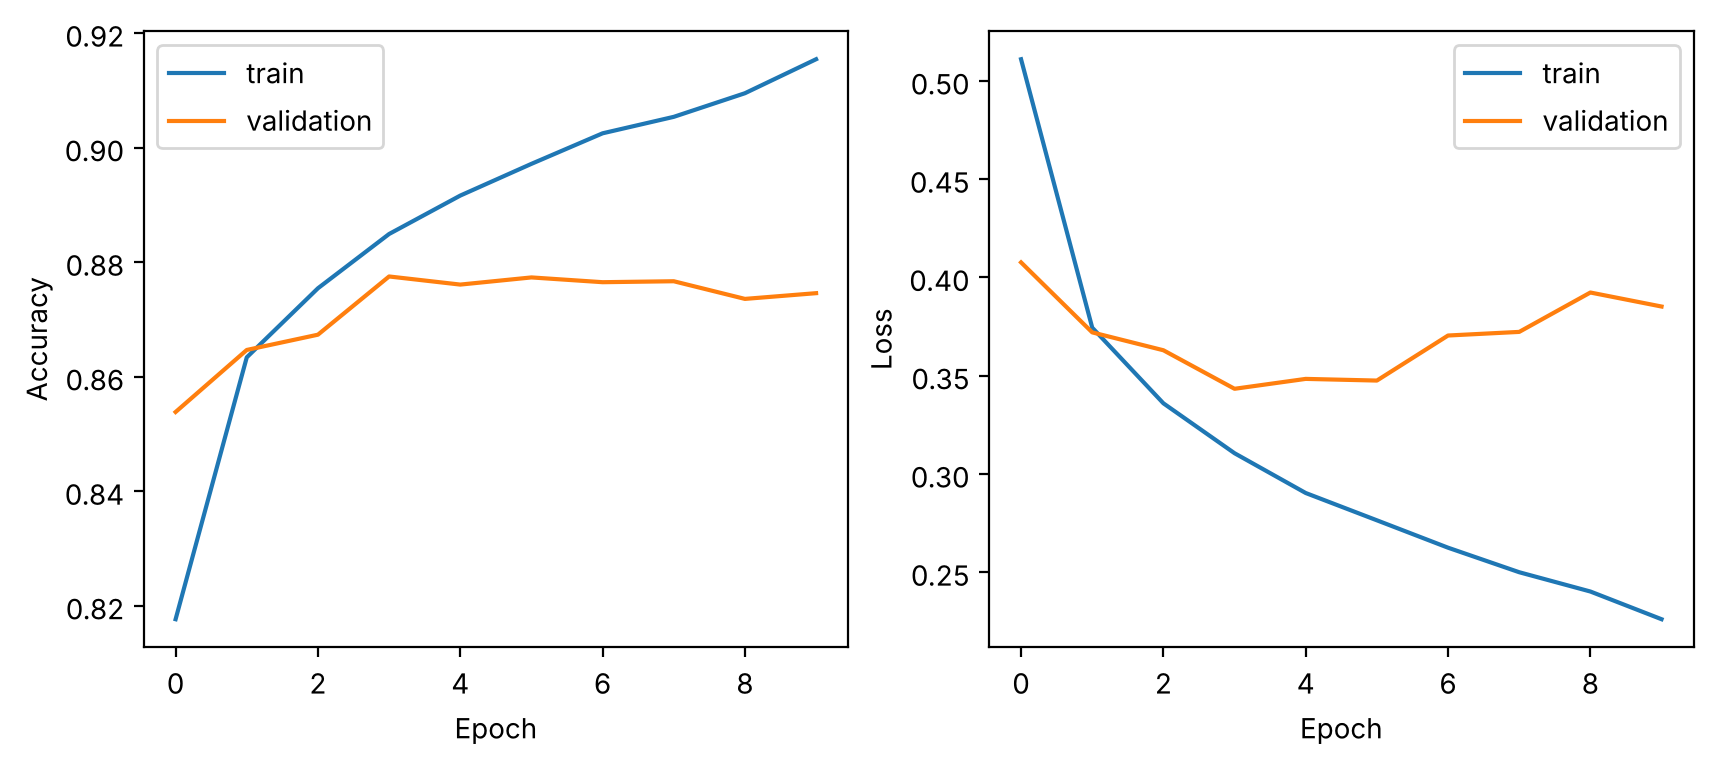

In [20]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.show()

### 3.8 Step 7: Make Predictions

Predicted: Ankle boot
Actual:    Ankle boot


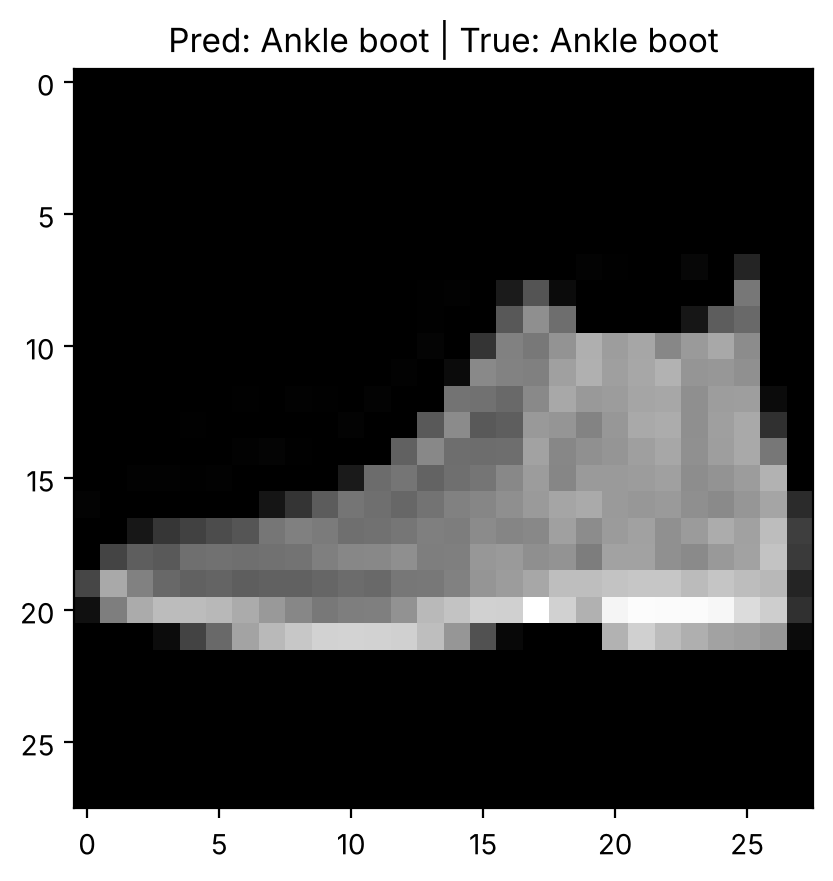

In [21]:
predictions = model.predict(x_test, verbose=0)

i = 0
pred_label = np.argmax(predictions[i])
print("Predicted:", class_names[pred_label])
print("Actual:   ", class_names[y_test[i]])

plt.imshow(x_test[i], cmap="gray")
plt.title(f"Pred: {class_names[pred_label]} | True: {class_names[y_test[i]]}")
plt.show()

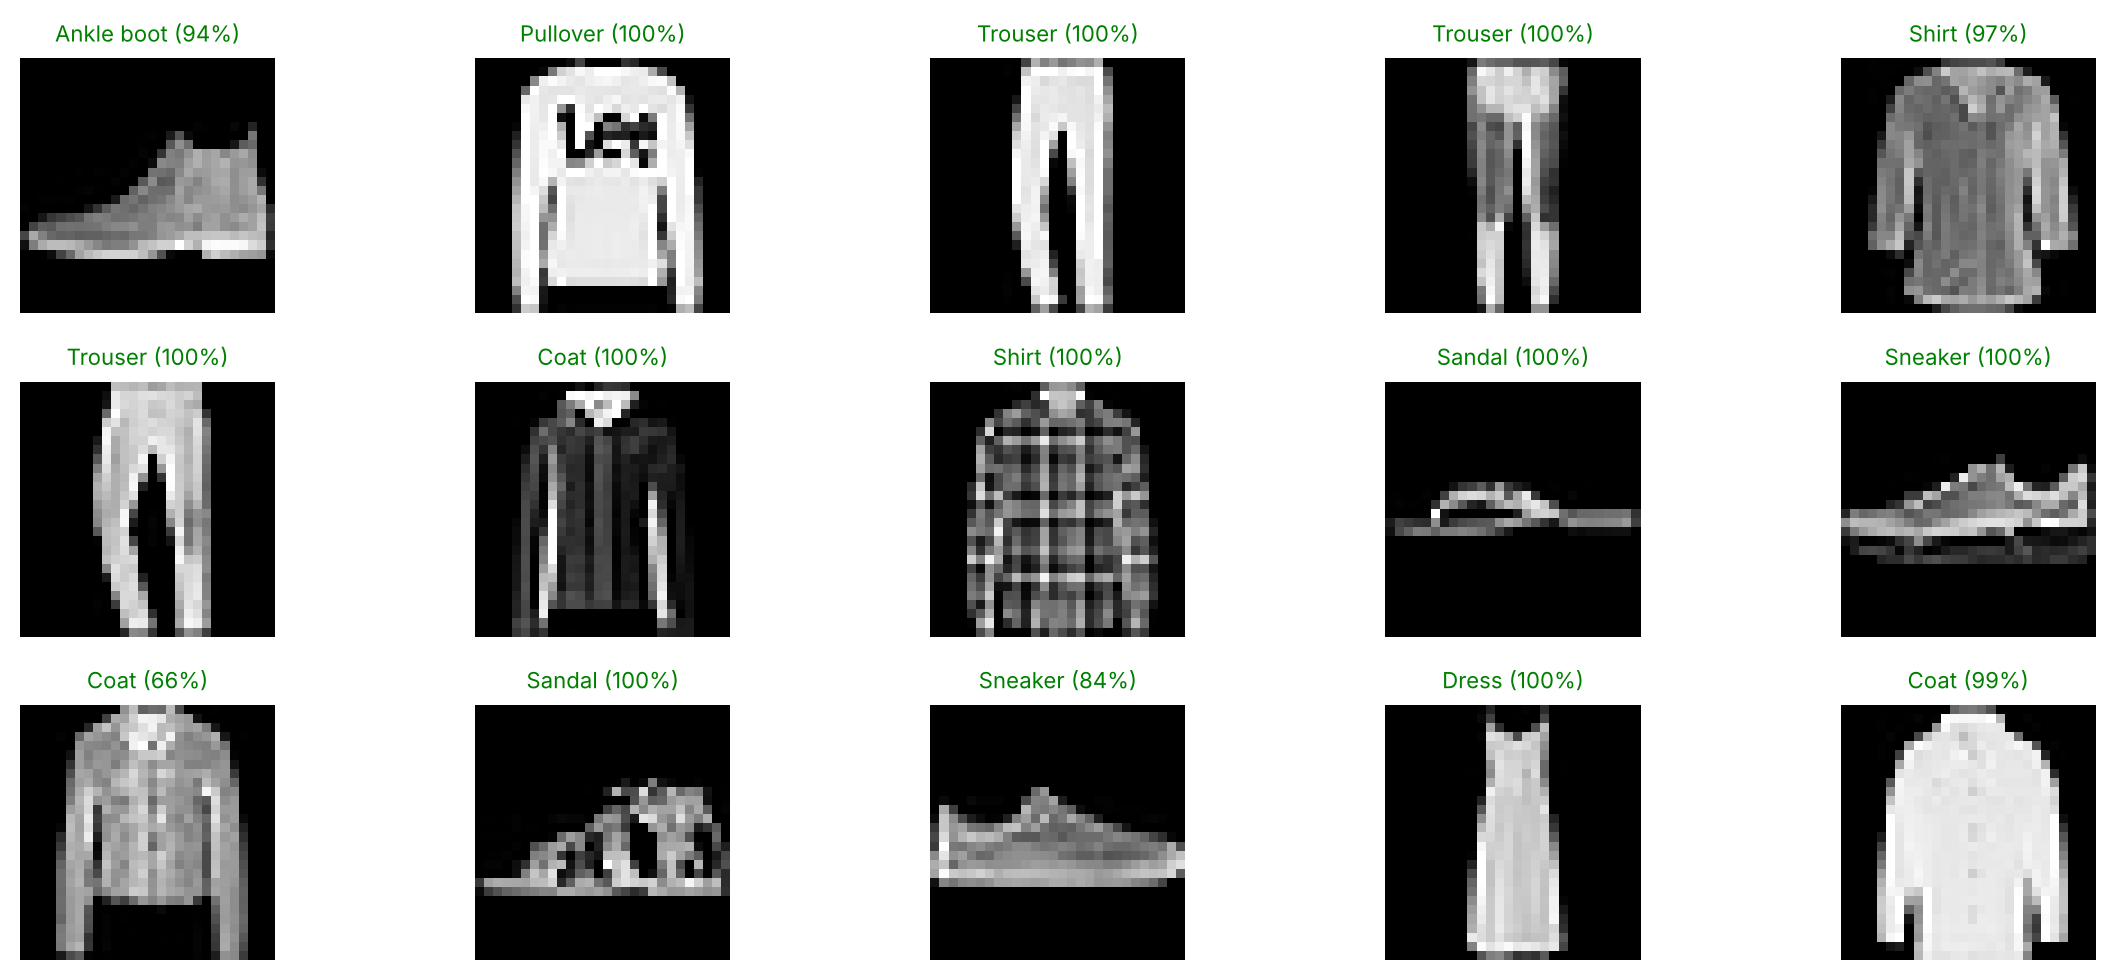

In [22]:
# A few more test predictions (green = correct, red = wrong)
plt.figure(figsize=(12, 5))
for k in range(15):
    p = np.argmax(predictions[k])
    plt.subplot(3, 5, k + 1)
    plt.imshow(x_test[k], cmap="gray")
    plt.title(f"{class_names[p]} ({np.max(predictions[k]):.0%})",
              color="green" if p == y_test[k] else "red", fontsize=8)
    plt.axis("off")
plt.tight_layout(); plt.show()

### 3.9 Step 8: Predict on Your Own Image (Connecting Parts 1 to 3)
Fashion-MNIST items are white on a black background. `my_clothing.jpg` has a white background, so it is inverted.

Prediction: Shirt (74.7% confidence)
Top 3: [('Shirt', '74.7%'), ('T-shirt', '23.7%'), ('Coat', '0.7%')]


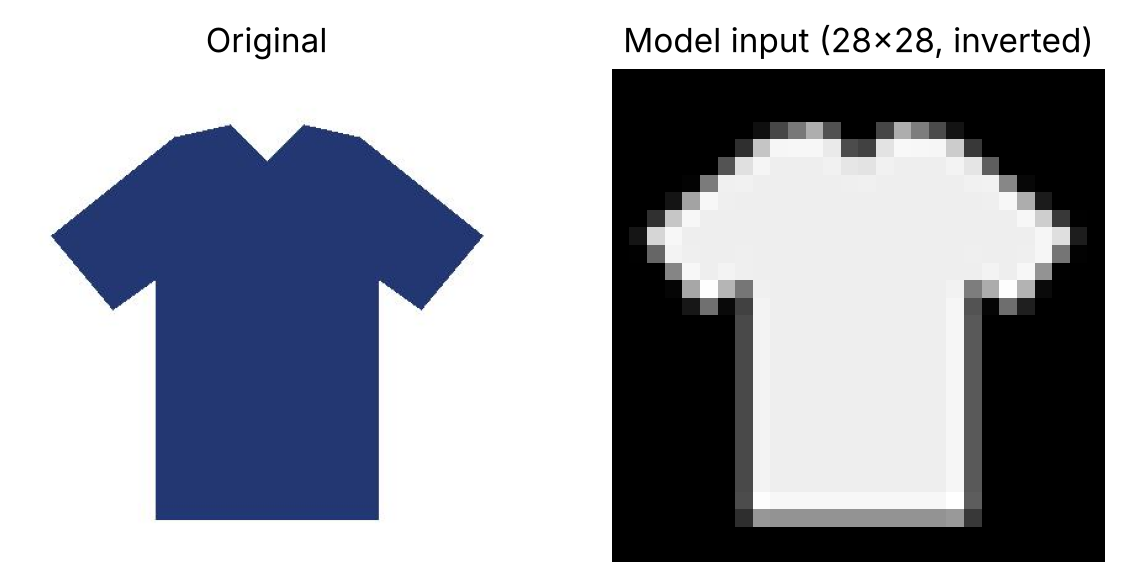

In [23]:
img = Image.open("my_clothing.jpg").convert("L").resize((28, 28))
img = ImageOps.invert(img)   # background is white, so invert

arr = np.array(img).astype("float32") / 255.0   # SAME normalization as training
arr = arr.reshape(1, 28, 28)                    # add batch dimension

pred = model.predict(arr, verbose=0)
print("Prediction:", class_names[np.argmax(pred)],
      f"({np.max(pred):.1%} confidence)")

top3 = np.argsort(pred[0])[::-1][:3]
print("Top 3:", [(class_names[c], f"{pred[0][c]:.1%}") for c in top3])

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(Image.open("my_clothing.jpg")); ax[0].set_title("Original"); ax[0].axis("off")
ax[1].imshow(arr[0], cmap="gray"); ax[1].set_title("Model input (28x28, inverted)"); ax[1].axis("off")
plt.show()

> **Key lesson:** any preprocessing used in training (resize, grayscale, scaling) must be applied identically at prediction time.

### Task 3 (Part 3)
**3.1 Final training, validation and test accuracy**

In [24]:
results_31 = pd.DataFrame({
    "Train accuracy": [history.history["accuracy"][-1]],
    "Validation accuracy": [history.history["val_accuracy"][-1]],
    "Test accuracy": [test_acc],
    "Test loss": [test_loss],
}, index=["Normalized, 128-64, 10 epochs"]).round(4)
display(results_31)

,Train accuracy,Validation accuracy,Test accuracy,Test loss
"Normalized, 128-64, 10 epochs",0.9154,0.8746,0.8701,0.3994


**3.2 Normalization experiment: same architecture on unnormalized data (0 to 255)**

In [25]:
tf.keras.utils.set_random_seed(42)

model_raw = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
model_raw.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

history_raw = model_raw.fit(x_train_raw.astype("float32"), y_train, epochs=10, batch_size=32,
                            validation_split=0.2, verbose=2)
raw_test_loss, raw_test_acc = model_raw.evaluate(x_test_raw.astype("float32"), y_test, verbose=0)
print(f"Unnormalized test accuracy: {raw_test_acc:.4f}   (normalized: {test_acc:.4f})")

Epoch 1/10


1500/1500 - 5s - 3ms/step - accuracy: 0.7421 - loss: 2.6299 - val_accuracy: 0.7627 - val_loss: 0.7430


Epoch 2/10


1500/1500 - 4s - 3ms/step - accuracy: 0.8034 - loss: 0.6049 - val_accuracy: 0.7972 - val_loss: 0.5845


Epoch 3/10


1500/1500 - 4s - 3ms/step - accuracy: 0.8177 - loss: 0.5344 - val_accuracy: 0.8231 - val_loss: 0.5362


... (11 outputs left out)

1500/1500 - 4s - 3ms/step - accuracy: 0.8548 - loss: 0.4074 - val_accuracy: 0.8509 - val_loss: 0.4357


Epoch 10/10


1500/1500 - 4s - 3ms/step - accuracy: 0.8611 - loss: 0.3896 - val_accuracy: 0.8557 - val_loss: 0.4176


Unnormalized test accuracy: 0.8444   (normalized: 0.8701)


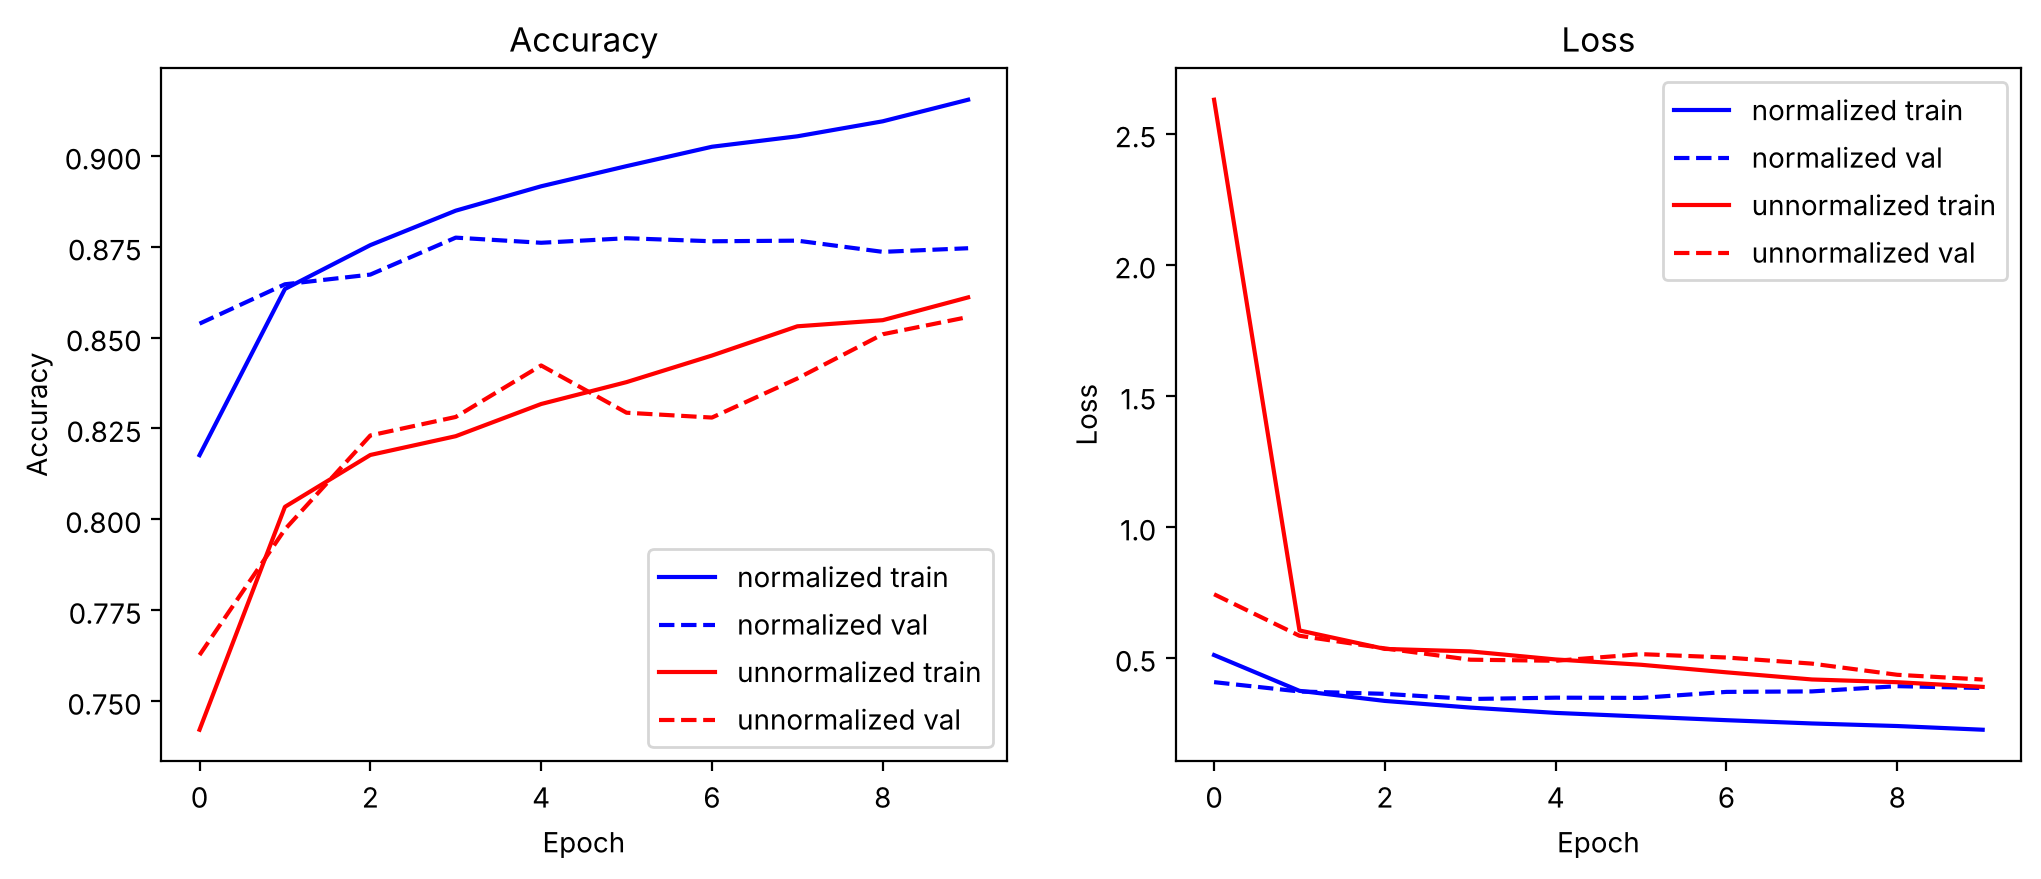

,Epoch-1 train loss,Final train acc,Final val acc,Final val loss,Test acc
Normalized (0-1),0.5110,0.9154,0.8746,0.3852,0.8701
Unnormalized (0-255),2.6299,0.8611,0.8557,0.4176,0.8444


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(history.history["accuracy"], "b-", label="normalized train")
ax[0].plot(history.history["val_accuracy"], "b--", label="normalized val")
ax[0].plot(history_raw.history["accuracy"], "r-", label="unnormalized train")
ax[0].plot(history_raw.history["val_accuracy"], "r--", label="unnormalized val")
ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].set_title("Accuracy"); ax[0].legend()

ax[1].plot(history.history["loss"], "b-", label="normalized train")
ax[1].plot(history.history["val_loss"], "b--", label="normalized val")
ax[1].plot(history_raw.history["loss"], "r-", label="unnormalized train")
ax[1].plot(history_raw.history["val_loss"], "r--", label="unnormalized val")
ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].set_title("Loss"); ax[1].legend()
plt.show()

cmp = pd.DataFrame({
    "Epoch-1 train loss": [history.history["loss"][0], history_raw.history["loss"][0]],
    "Final train acc": [history.history["accuracy"][-1], history_raw.history["accuracy"][-1]],
    "Final val acc": [history.history["val_accuracy"][-1], history_raw.history["val_accuracy"][-1]],
    "Final val loss": [history.history["val_loss"][-1], history_raw.history["val_loss"][-1]],
    "Test acc": [test_acc, raw_test_acc],
}, index=["Normalized (0-1)", "Unnormalized (0-255)"]).round(4)
display(cmp)

**Answer:**

| | Normalized (0 to 1) | Unnormalized (0 to 255) |
|---|---|---|
| Epoch-1 training loss | 0.511 | **2.630** |
| Final train accuracy | 0.9154 | 0.8611 |
| Final val accuracy | 0.8746 | 0.8557 |
| Test accuracy | **0.8701** | 0.8444 |

The normalized model learns faster and ends about 2.6 points higher on the test set. The unnormalized model starts with a much bigger loss (2.63 vs 0.51 in epoch 1), and its validation accuracy moves around more (for example 0.842, then 0.829, then 0.828).

**Why:** with inputs up to 255, the weighted sums in the first layer are about 255 times larger than with inputs in [0, 1]. The Glorot weight initialisation assumes small inputs, so the softmax outputs saturate early. That gives very confident wrong predictions, a large loss and large, uneven gradients. Adam's per-parameter step sizes let it recover, which is why it still reaches about 84%, but optimisation is slower and noisier. Its curves are still rising at epoch 10, so more epochs would close part of the gap. Normalization simply gets there faster and more reliably.

**3.3 Architecture experiment**
One factor is changed at a time from the baseline (2 hidden layers, 128 neurons each, 10 epochs). Same seed for every run.

In [27]:
def build_model(n_layers=2, units=128, dropout=None):
    layers = [tf.keras.layers.Input(shape=(28, 28)), tf.keras.layers.Flatten()]
    for _ in range(n_layers):
        layers.append(tf.keras.layers.Dense(units, activation="relu"))
        if dropout:
            layers.append(tf.keras.layers.Dropout(dropout))
    layers.append(tf.keras.layers.Dense(10, activation="softmax"))
    m = tf.keras.Sequential(layers)
    m.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def run_experiment(name, n_layers=2, units=128, epochs=10, dropout=None):
    tf.keras.utils.set_random_seed(42)
    m = build_model(n_layers, units, dropout)
    t0 = time.time()
    h = m.fit(x_train, y_train, epochs=epochs, batch_size=32, validation_split=0.2, verbose=0)
    secs = time.time() - t0
    _, t_acc = m.evaluate(x_test, y_test, verbose=0)
    row = {"Experiment": name, "Hidden layers": n_layers, "Neurons/layer": units, "Epochs": epochs,
           "Params": m.count_params(),
           "Train acc": h.history["accuracy"][-1], "Val acc": h.history["val_accuracy"][-1],
           "Test acc": t_acc, "Gap (train-val)": h.history["accuracy"][-1] - h.history["val_accuracy"][-1],
           "Time (s)": secs}
    print(f"{name:28s} train={row['Train acc']:.4f} val={row['Val acc']:.4f} test={t_acc:.4f} ({secs:.0f}s)")
    return row, h

configs = [
    ("Layers = 1",            dict(n_layers=1, units=128, epochs=10)),
    ("Layers = 2 (baseline)", dict(n_layers=2, units=128, epochs=10)),
    ("Layers = 3",            dict(n_layers=3, units=128, epochs=10)),
    ("Neurons = 32",          dict(n_layers=2, units=32,  epochs=10)),
    ("Neurons = 256",         dict(n_layers=2, units=256, epochs=10)),
    ("Epochs = 5",            dict(n_layers=2, units=128, epochs=5)),
    ("Epochs = 20",           dict(n_layers=2, units=128, epochs=20)),
]

rows, arch_histories = [], {}
for name, cfg in configs:
    row, h = run_experiment(name, **cfg)
    rows.append(row); arch_histories[name] = h

Layers = 1                   train=0.9135 val=0.8838 test=0.8734 (38s)


Layers = 2 (baseline)        train=0.9159 val=0.8807 test=0.8727 (44s)


Layers = 3                   train=0.9115 val=0.8789 test=0.8711 (44s)


Neurons = 32                 train=0.8942 val=0.8702 test=0.8583 (32s)


Neurons = 256                train=0.9173 val=0.8844 test=0.8757 (51s)


Epochs = 5                   train=0.8924 val=0.8777 test=0.8661 (22s)


Epochs = 20                  train=0.9419 val=0.8760 test=0.8699 (85s)


,Hidden layers,Neurons/layer,Epochs,Params,Train acc,Val acc,Test acc,Gap (train-val),Time (s)
Experiment,,,,,,,,,
Layers = 1,1,128,10,"101,770",0.9135,0.8838,0.8734,0.0298,38
Layers = 2 (baseline),2,128,10,"118,282",0.9159,0.8807,0.8727,0.0352,44
Layers = 3,3,128,10,"134,794",0.9115,0.8789,0.8711,0.0326,44
Neurons = 32,2,32,10,"26,506",0.8942,0.8702,0.8583,0.0241,32
Neurons = 256,2,256,10,"269,322",0.9173,0.8844,0.8757,0.0329,51
Epochs = 5,2,128,5,"118,282",0.8924,0.8777,0.8661,0.0147,22
Epochs = 20,2,128,20,"118,282",0.9419,0.8760,0.8699,0.0659,85


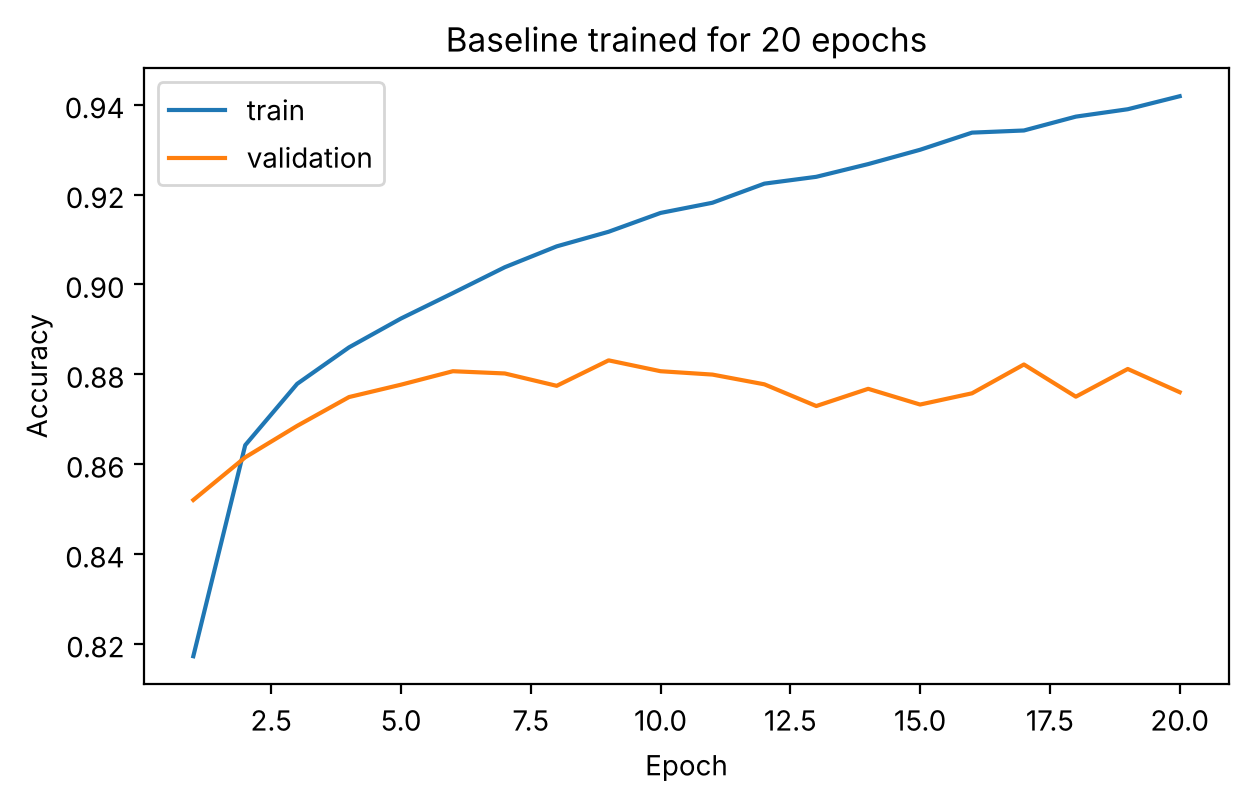

In [28]:
arch_table = pd.DataFrame(rows).set_index("Experiment")
display(arch_table.style.format({
    "Params": "{:,}", "Train acc": "{:.4f}", "Val acc": "{:.4f}", "Test acc": "{:.4f}",
    "Gap (train-val)": "{:.4f}", "Time (s)": "{:.0f}"}))

h20 = arch_histories["Epochs = 20"]
plt.figure(figsize=(7, 4))
plt.plot(range(1, 21), h20.history["accuracy"], label="train")
plt.plot(range(1, 21), h20.history["val_accuracy"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Baseline trained for 20 epochs"); plt.legend()
plt.show()

**Answer:**

Every run changes one factor from the baseline (2 hidden layers x 128 neurons, 10 epochs). This baseline differs slightly from the 128-64 model in 3.4, which is why it has its own row.

| Experiment | Hidden layers | Neurons | Epochs | Params | Train acc | Val acc | Test acc |
|---|---|---|---|---|---|---|---|
| Layers = 1 | 1 | 128 | 10 | 101,770 | 0.9135 | 0.8838 | 0.8734 |
| Layers = 2 (baseline) | 2 | 128 | 10 | 118,282 | 0.9159 | 0.8807 | 0.8727 |
| Layers = 3 | 3 | 128 | 10 | 134,794 | 0.9115 | 0.8789 | 0.8711 |
| Neurons = 32 | 2 | 32 | 10 | 26,506 | 0.8942 | 0.8702 | 0.8583 |
| Neurons = 256 | 2 | 256 | 10 | 269,322 | 0.9173 | 0.8844 | **0.8757** |
| Epochs = 5 | 2 | 128 | 5 | 118,282 | 0.8924 | 0.8777 | 0.8661 |
| Epochs = 20 | 2 | 128 | 20 | 118,282 | **0.9419** | 0.8760 | 0.8699 |

**Observations**
* **Depth:** 1, 2 and 3 hidden layers all land around 87.1 to 87.3% test accuracy. On this dataset, extra dense layers add parameters and time but no accuracy.
* **Width:** 32 neurons is too small. It underfits (train accuracy is only 0.894) and gives the lowest test accuracy, 85.8%. 256 neurons is the best run at 87.6%, but it needs more than twice the parameters of 128 for a 0.3 point gain, so the returns are diminishing.
* **Epochs:** 5 epochs is slightly undertrained (86.6%). With 20 epochs, train accuracy climbs to 94.2% while validation stays around 87.6%, and the train/val gap grows from 0.035 to 0.066. The 20-epoch plot shows validation accuracy flattening after about epoch 6 to 10, so the extra epochs only memorise the training set (overfitting). About 10 epochs, or early stopping on `val_loss`, is the sensible choice.

**3.4 Dropout(0.2) after each hidden layer: does overfitting shrink?**

Layers = 2 + Dropout(0.2)    train=0.8876 val=0.8786 test=0.8713 (44s)


,Train acc,Val acc,Test acc,Gap (train-val)
No dropout,0.9159,0.8807,0.8727,0.0352
Dropout 0.2,0.8876,0.8786,0.8713,0.0091


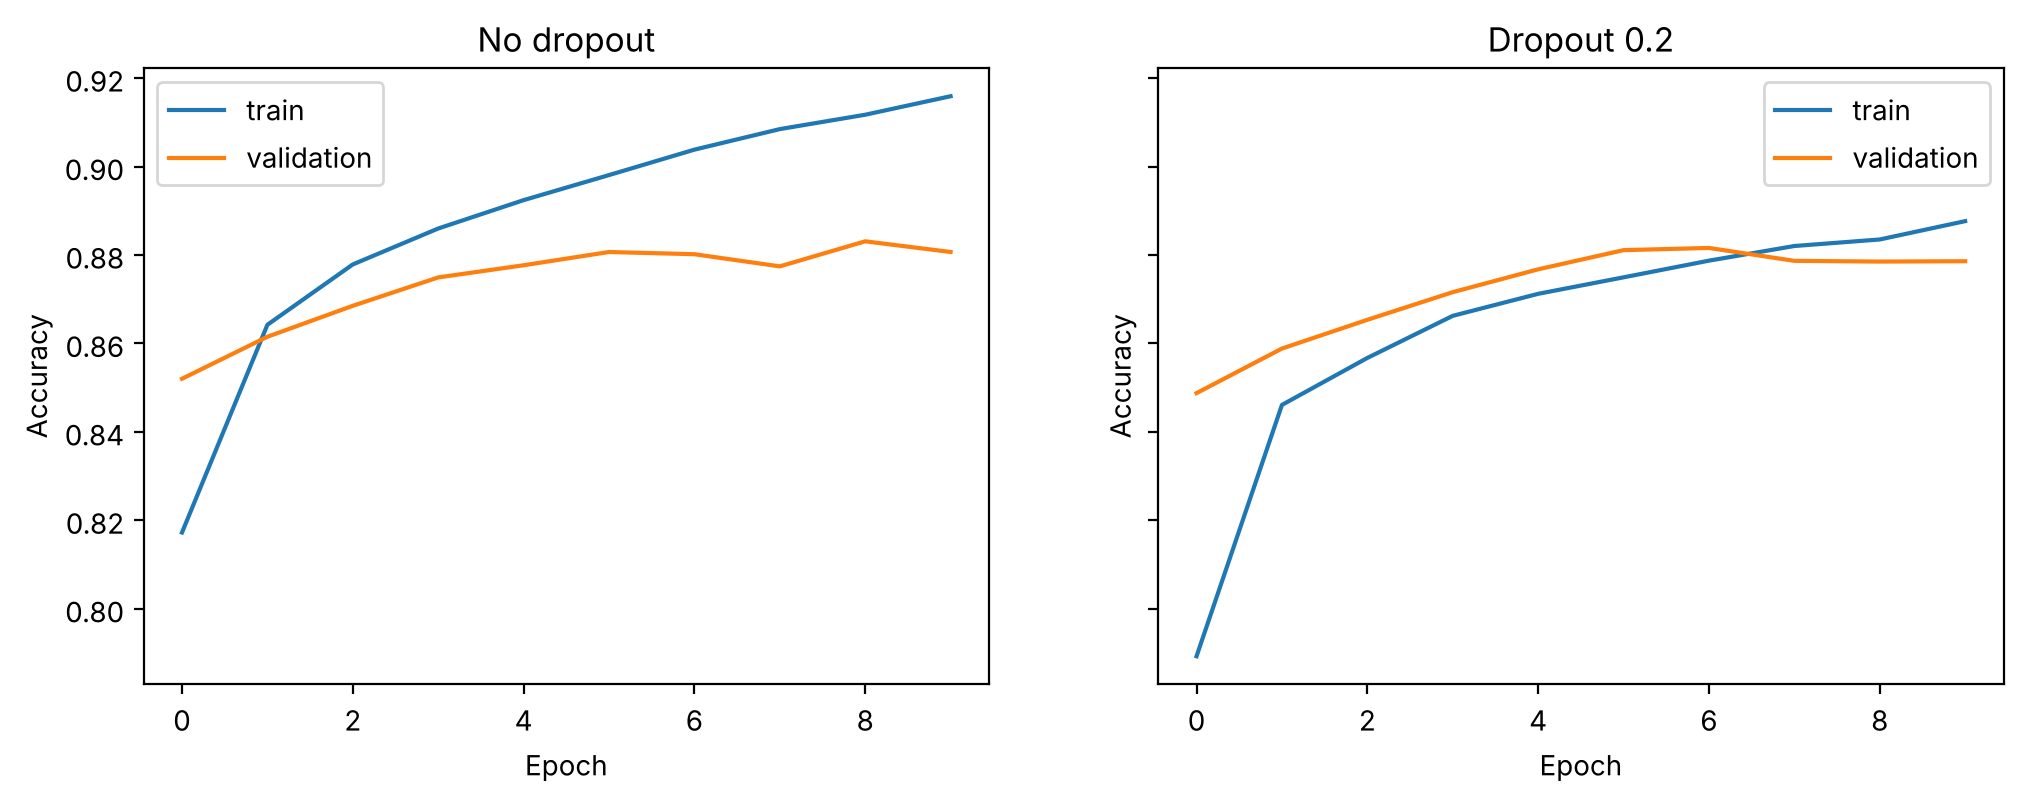

In [29]:
row_do, h_do = run_experiment("Layers = 2 + Dropout(0.2)", n_layers=2, units=128, epochs=10, dropout=0.2)
h_base = arch_histories["Layers = 2 (baseline)"]
base = arch_table.loc["Layers = 2 (baseline)"]

do_table = pd.DataFrame({
    "Train acc": [base["Train acc"], row_do["Train acc"]],
    "Val acc": [base["Val acc"], row_do["Val acc"]],
    "Test acc": [base["Test acc"], row_do["Test acc"]],
    "Gap (train-val)": [base["Gap (train-val)"], row_do["Gap (train-val)"]],
}, index=["No dropout", "Dropout 0.2"]).round(4)
display(do_table)

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (title, h) in zip(ax, [("No dropout", h_base), ("Dropout 0.2", h_do)]):
    a.plot(h.history["accuracy"], label="train"); a.plot(h.history["val_accuracy"], label="validation")
    a.set_title(title); a.set_xlabel("Epoch"); a.set_ylabel("Accuracy"); a.legend()
plt.show()

**Answer:**

**Yes.** The train/validation gap dropped from **0.0352 to 0.0091**, about 4 times smaller. Training accuracy fell (0.9159 to 0.8876) because dropout randomly switches off 20% of the hidden activations at each training step, so the network can't rely on any single neuron and memorises less. Validation and test accuracy stayed essentially the same (0.8807 vs 0.8786 val, 0.8727 vs 0.8713 test). In the dropout curves, validation accuracy sits at or above training accuracy for most epochs. At 10 epochs, dropout reduced overfitting without improving test accuracy. Its real payoff is in longer training, such as the 20-epoch run, where the plain model's gap grew to 0.066.

**3.5 Challenge: confusion matrix**

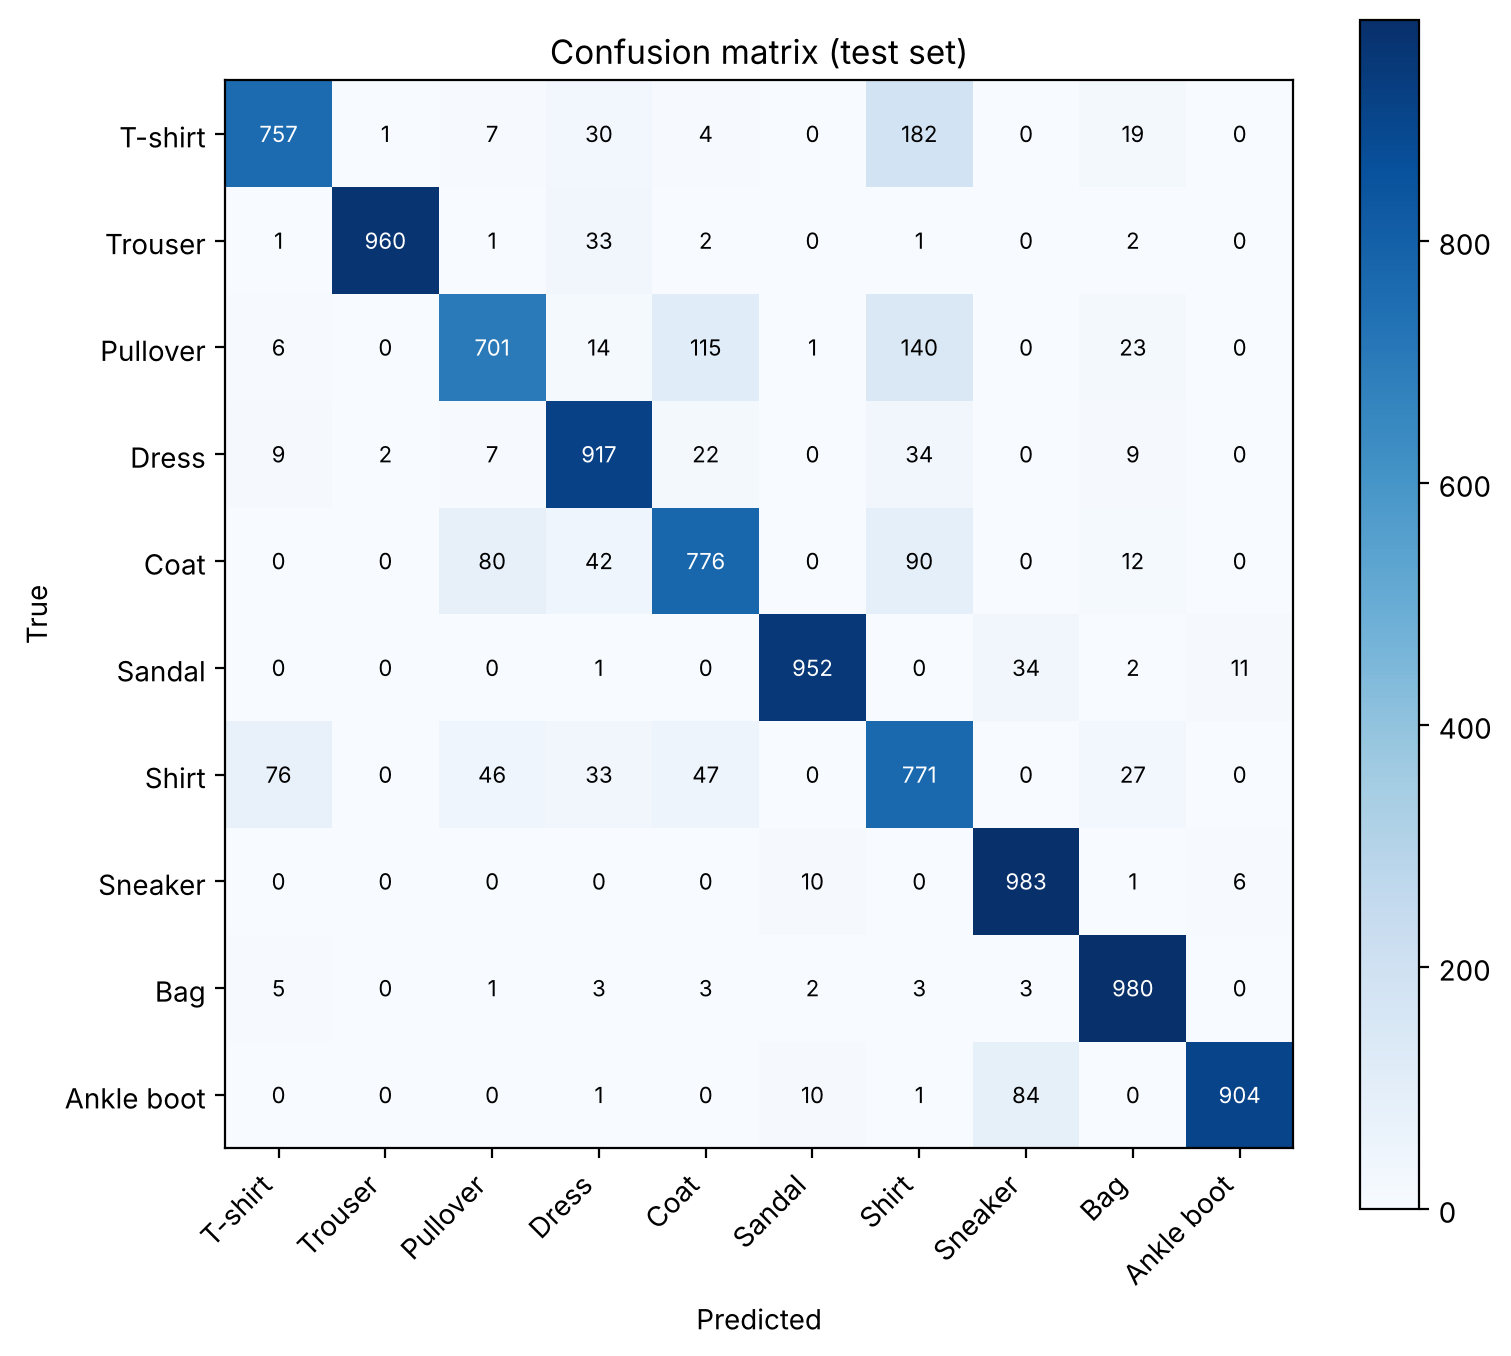

Most confused class pairs (errors in both directions):
  T-shirt    <-> Shirt     : 258
  Pullover   <-> Coat      : 195
  Pullover   <-> Shirt     : 186
  Coat       <-> Shirt     : 137
  Sneaker    <-> Ankle boot: 90

Per-class accuracy:
  T-shirt    0.757
  Trouser    0.960
  Pullover   0.701
  Dress      0.917
  Coat       0.776
  Sandal     0.952
  Shirt      0.771
  Sneaker    0.983
  Bag        0.980
  Ankle boot 0.904


In [30]:
from sklearn.metrics import confusion_matrix

y_pred = np.argmax(model.predict(x_test, verbose=0), axis=1)
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(class_names)
for r in range(10):
    for c in range(10):
        ax.text(c, r, cm[r, c], ha="center", va="center", fontsize=8,
                color="white" if cm[r, c] > cm.max() / 2 else "black")
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test set)")
fig.colorbar(im); plt.tight_layout(); plt.show()

off = cm.copy(); np.fill_diagonal(off, 0)
pairs = [(off[a, b] + off[b, a], class_names[a], class_names[b]) for a in range(10) for b in range(a + 1, 10)]
pairs.sort(reverse=True)
print("Most confused class pairs (errors in both directions):")
for n, a, b in pairs[:5]:
    print(f"  {a:10s} <-> {b:10s}: {n}")
print("\nPer-class accuracy:")
for k in range(10):
    print(f"  {class_names[k]:10s} {cm[k, k] / cm[k].sum():.3f}")

**Answer:**

The most confused pair is **T-shirt and Shirt**, with 258 errors in total: 182 T-shirts were predicted as Shirt and 76 Shirts as T-shirt. Next come **Pullover and Coat** (195) and **Pullover and Shirt** (186). The weakest classes are Pullover (70.1%), T-shirt (75.7%), Shirt (77.1%) and Coat (77.6%). Trousers, Bags, Sneakers and Sandals all score above 95%.

**Why:** at 28x28 grayscale, all upper-body garments share almost the same outline: a torso with two sleeves. What separates them is fine detail such as collars, buttons, zips, sleeve length and fabric texture, and much of that is lost at this resolution. On top of that, a dense network looks at pixels independently and has no built-in sense of local shape or texture. The same thing happened with my own image in 3.9: the drawn T-shirt was classified as **Shirt (74.7%)**, with T-shirt second at 23.7%. Sneaker and Ankle boot (90 errors) is the footwear version of the same problem.

## Part 4: Standardization with a Keras Layer (Optional Extension)
The Keras `Normalization` layer learns the mean and variance from the training data and becomes part of the model.

In [31]:
(x_tr, y_tr), (x_te, y_te) = tf.keras.datasets.fashion_mnist.load_data()
x_tr = x_tr.astype("float32")
x_te = x_te.astype("float32")

norm_layer = tf.keras.layers.Normalization(axis=None)
norm_layer.adapt(x_tr)   # learns mean and variance from training data
print("Learned mean:", float(norm_layer.mean.numpy().squeeze()), " variance:", float(norm_layer.variance.numpy().squeeze()))

tf.keras.utils.set_random_seed(42)
model2 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    norm_layer,
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax")
])
model2.compile(optimizer="adam",
               loss="sparse_categorical_crossentropy",
               metrics=["accuracy"])
model2.fit(x_tr, y_tr, epochs=5, validation_split=0.2, verbose=2)
print(model2.evaluate(x_te, y_te, verbose=0))

Learned mean: 72.94035339355469  variance: 8103.8134765625
Epoch 1/5


1500/1500 - 4s - 3ms/step - accuracy: 0.8286 - loss: 0.4744 - val_accuracy: 0.8530 - val_loss: 0.3997


Epoch 2/5


1500/1500 - 6s - 4ms/step - accuracy: 0.8678 - loss: 0.3629 - val_accuracy: 0.8640 - val_loss: 0.3703


Epoch 3/5


1500/1500 - 6s - 4ms/step - accuracy: 0.8803 - loss: 0.3242 - val_accuracy: 0.8712 - val_loss: 0.3567


Epoch 4/5


1500/1500 - 4s - 3ms/step - accuracy: 0.8905 - loss: 0.2976 - val_accuracy: 0.8752 - val_loss: 0.3503


Epoch 5/5


1500/1500 - 4s - 3ms/step - accuracy: 0.8980 - loss: 0.2765 - val_accuracy: 0.8750 - val_loss: 0.3528


[0.3907323479652405, 0.8623999953269958]


In [32]:
# The model takes raw 0-255 pixels directly, no manual scaling needed at prediction time
raw_clothing = np.array(ImageOps.invert(Image.open("my_clothing.jpg").convert("L").resize((28, 28))), dtype="float32")
p2 = model2.predict(raw_clothing.reshape(1, 28, 28), verbose=0)
print("model2 on raw my_clothing.jpg:", class_names[np.argmax(p2)], f"({np.max(p2):.1%})")

model2 on raw my_clothing.jpg: T-shirt (50.2%)


**Discussion:** advantage of putting normalization inside the model

**Answer:**

With the `Normalization` layer, the scaling statistics (here mean 72.94 and variance 8103.8, so std about 90.0) are learned once from the **training data only** via `adapt()` and are **saved as part of the model**. Advantages:
* **It can't be forgotten or done wrong at prediction time.** The model takes raw 0 to 255 pixels, as shown above where `model2` classified the raw `my_clothing.jpg` with no manual scaling. With manual preprocessing, forgetting the `/255` (or using different statistics) silently breaks predictions.
* **No leakage:** the statistics come from the training set by design.
* **Portability:** a saved or exported model (SavedModel, TFLite, TF Serving) carries its preprocessing with it, so deployment code doesn't need to know or copy it.

Performance is about the same as manual scaling: 86.2% test accuracy after 5 epochs with one hidden layer, compared with 86.6% for the 5-epoch manually scaled model in 3.3.

## Appendix: Cat vs. Dog Image Dataset

### A.1 Download the Dataset
*Cats and Dogs (filtered)*: 2,000 training and 1,000 validation images, balanced.

Note: in Keras 3 (TensorFlow 2.16+), `get_file(..., extract=True)` returns the path of the **extracted folder**
(`cats_and_dogs_filtered_extracted`) instead of the zip, so the lab's `os.path.dirname(zip_path)` line points to the wrong place.
The code below handles both the old and new behaviour.

In [33]:
URL = "https://storage.googleapis.com/mledu-datasets/cats_and_dogs_filtered.zip"
zip_path = tf.keras.utils.get_file("cats_and_dogs_filtered.zip", origin=URL, extract=True)

if os.path.isdir(os.path.join(zip_path, "cats_and_dogs_filtered")):      # Keras 3
    base_dir = os.path.join(zip_path, "cats_and_dogs_filtered")
else:                                                                    # older Keras
    base_dir = os.path.join(os.path.dirname(zip_path), "cats_and_dogs_filtered")

train_dir = os.path.join(base_dir, "train")
val_dir = os.path.join(base_dir, "validation")
print("base_dir:", base_dir)

for split_dir in (train_dir, val_dir):
    for cls in ("cats", "dogs"):
        n = len(os.listdir(os.path.join(split_dir, cls)))
        print(f"{os.path.basename(split_dir):>10} / {cls}: {n} images")

base_dir: /root/.keras/datasets/cats_and_dogs_filtered_extracted/cats_and_dogs_filtered
     train / cats: 1000 images
     train / dogs: 1000 images
validation / cats: 500 images
validation / dogs: 500 images


### A.2 Look at the Raw Data
The raw images have different sizes and aspect ratios, which is why resizing is required.

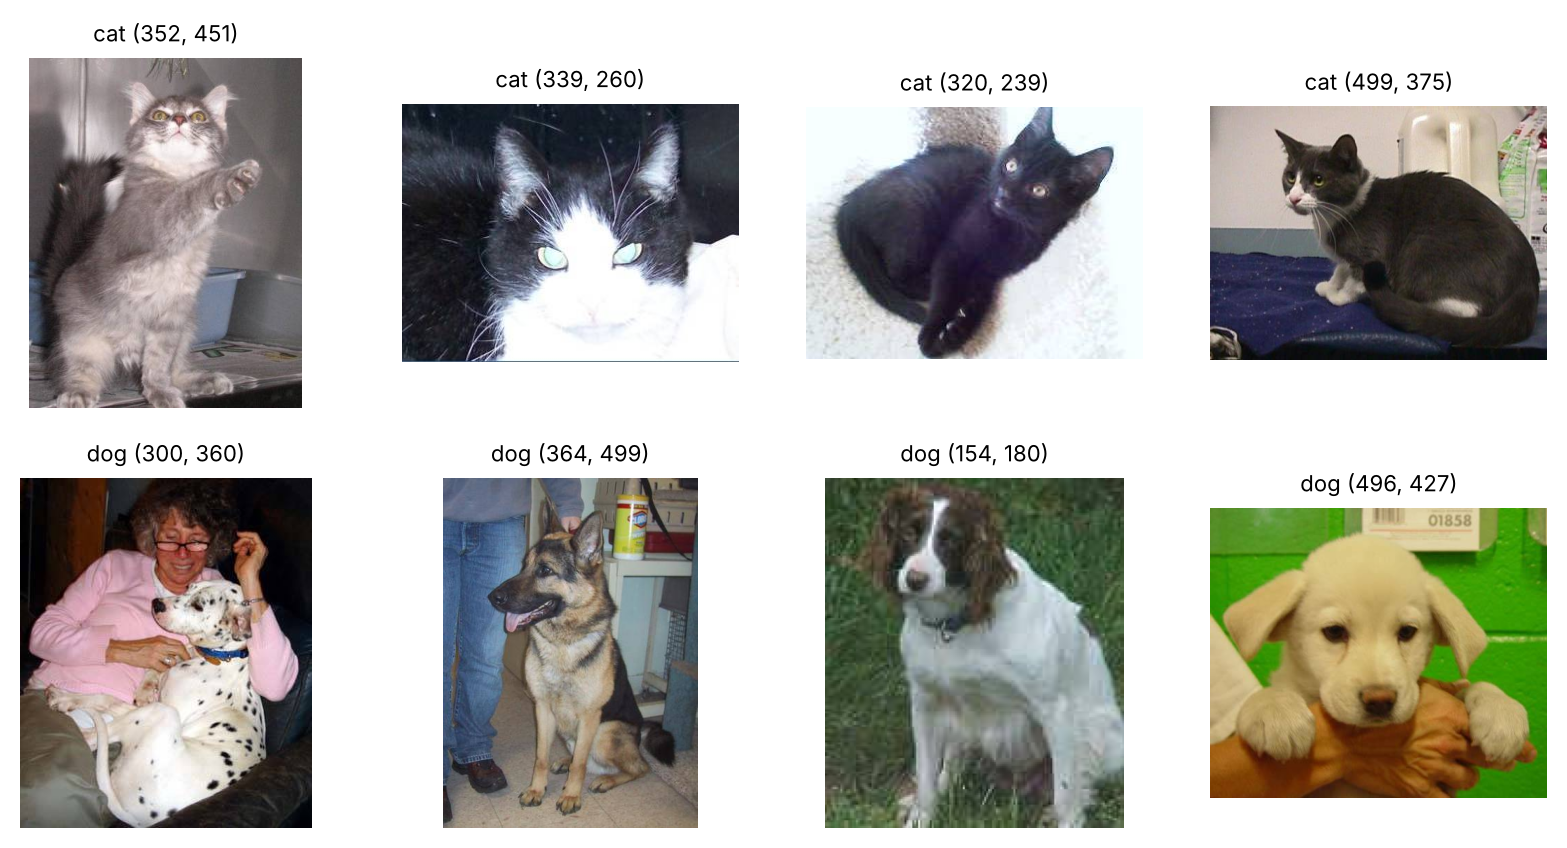

In [34]:
random.seed(42)
plt.figure(figsize=(10, 5))
for i, cls in enumerate(("cats", "dogs")):
    folder = os.path.join(train_dir, cls)
    files = random.sample(os.listdir(folder), 4)
    for j, f in enumerate(files):
        im = Image.open(os.path.join(folder, f))
        plt.subplot(2, 4, i * 4 + j + 1)
        plt.imshow(im)
        plt.title(f"{cls[:-1]} {im.size}", fontsize=8)
        plt.axis("off")
plt.show()

### A.3 Load, Resize and Batch

In [35]:
IMG_SIZE = (64, 64)
BATCH = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir, image_size=IMG_SIZE, batch_size=BATCH,
    color_mode="grayscale", label_mode="binary", shuffle=True, seed=42)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir, image_size=IMG_SIZE, batch_size=BATCH,
    color_mode="grayscale", label_mode="binary", shuffle=False)

class_names_cd = train_ds.class_names
print(class_names_cd)   # ['cats', 'dogs']

# Speed up training by caching and prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

Found 2000 files belonging to 2 classes.


Found 1000 files belonging to 2 classes.


['cats', 'dogs']


Check one batch:

Batch shape: (32, 64, 64, 1)
Pixel range: 0.0 to 255.0


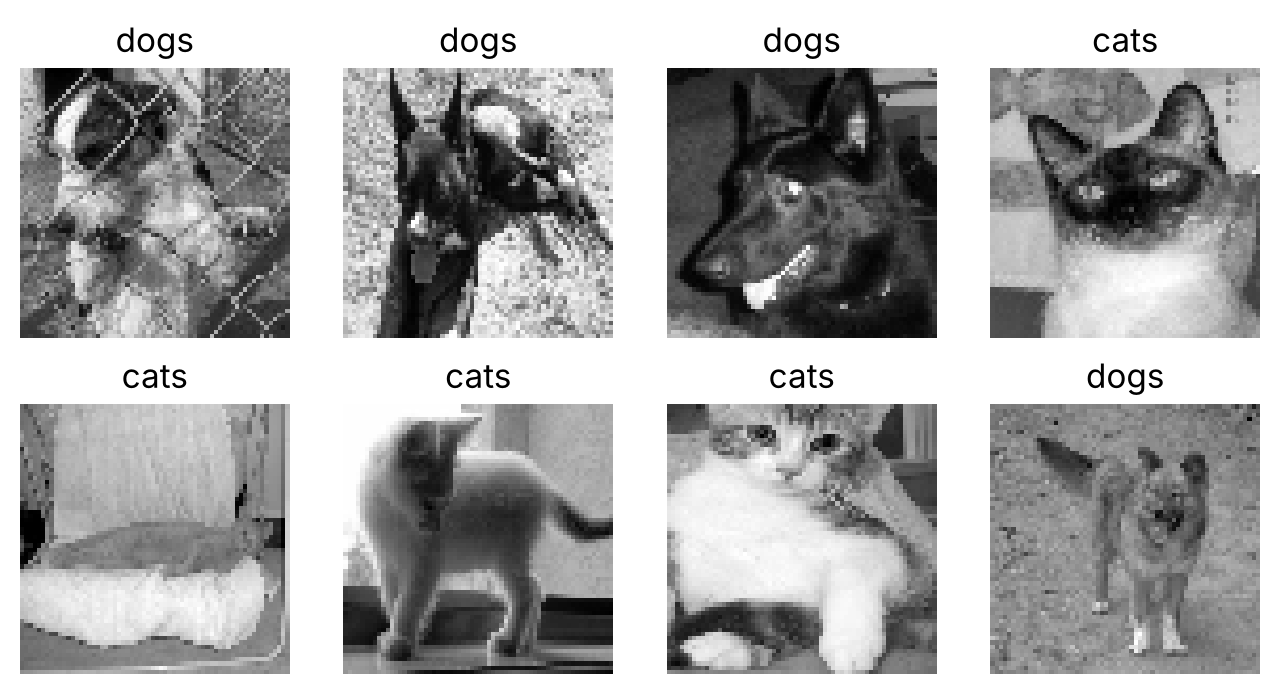

In [36]:
for images, labels in train_ds.take(1):
    print("Batch shape:", images.shape)   # (32, 64, 64, 1)
    print("Pixel range:", images.numpy().min(), "to", images.numpy().max())   # 0 to 255
    plt.figure(figsize=(8, 4))
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap="gray")
        plt.title(class_names_cd[int(labels[i].numpy()[0])])
        plt.axis("off")
    plt.show()

### A.4 Normalize and Train an ANN
The first layer rescales pixels to [0, 1], so normalization is also applied automatically at prediction time.

In [37]:
tf.keras.utils.set_random_seed(42)

model_cd = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 1)),
    tf.keras.layers.Rescaling(1.0 / 255),             # normalization
    tf.keras.layers.Flatten(),                        # 64*64 = 4096 inputs
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")    # 1 output: P(dog)
])

model_cd.compile(optimizer="adam",
                 loss="binary_crossentropy",   # two classes
                 metrics=["accuracy"])
model_cd.summary()

t0 = time.time()
history_cd = model_cd.fit(train_ds, validation_data=val_ds, epochs=15, verbose=2)
time_cd = time.time() - t0

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_11 (Flatten)            │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_32 (Dense)                │ (None, 128)            │       524,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_33 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_34 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 532,737 (2.03 MB)

 Trainable params: 532,737 (2.03 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


... (25 outputs left out)

Epoch 14/15


63/63 - 0s - 5ms/step - accuracy: 0.6160 - loss: 0.6536 - val_accuracy: 0.5870 - val_loss: 0.6660


Epoch 15/15


63/63 - 0s - 4ms/step - accuracy: 0.6035 - loss: 0.6578 - val_accuracy: 0.5990 - val_loss: 0.6668


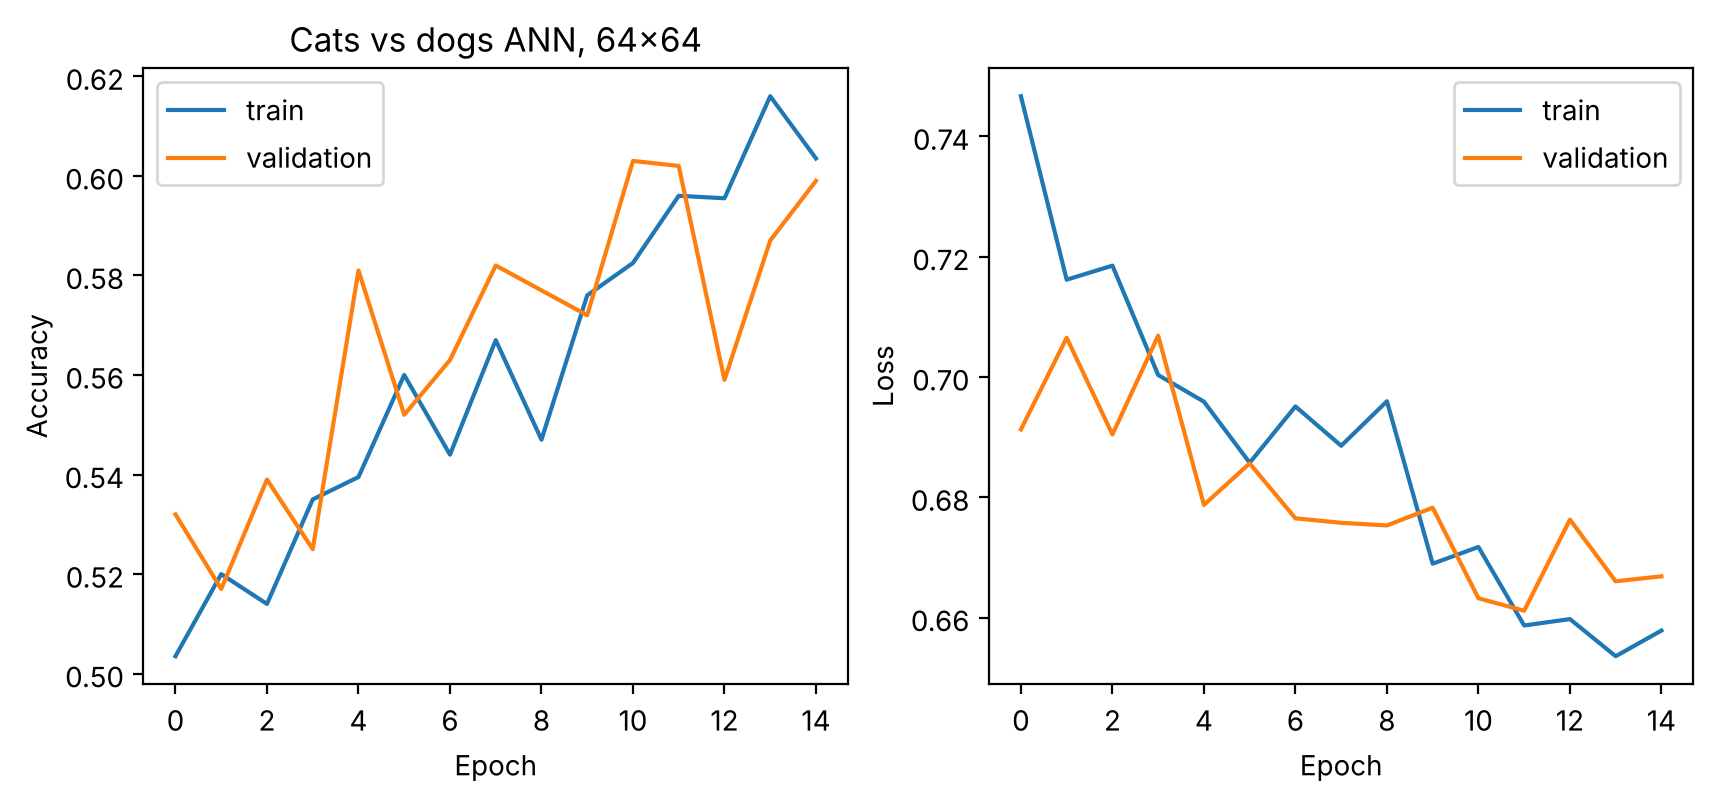

In [38]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cd.history["accuracy"], label="train"); plt.plot(history_cd.history["val_accuracy"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title("Cats vs dogs ANN, 64x64"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history_cd.history["loss"], label="train"); plt.plot(history_cd.history["val_loss"], label="validation")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
plt.show()

Differences from the Fashion-MNIST model: one sigmoid output instead of ten softmax outputs,
and binary cross-entropy instead of sparse categorical cross-entropy.

### A.5 Predict on a New Image

P(dog) = 0.60 -> dog


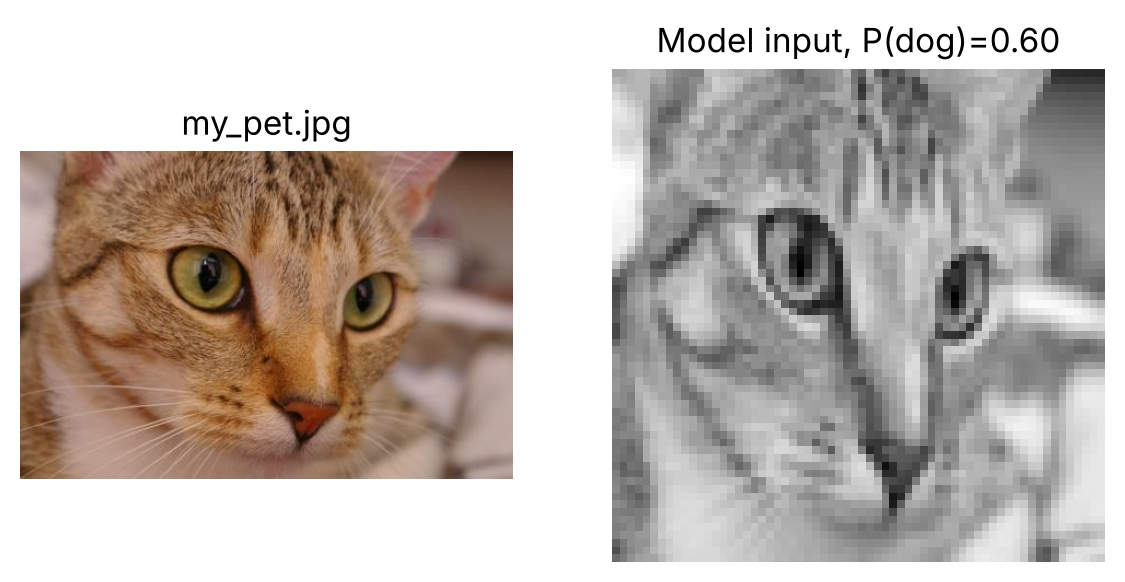

In [39]:
img = Image.open("my_pet.jpg").convert("L").resize((64, 64))
arr = np.array(img, dtype="float32").reshape(1, 64, 64, 1)   # no /255 here: the model rescales

p = model_cd.predict(arr, verbose=0)[0][0]
print(f"P(dog) = {p:.2f} -> {'dog' if p > 0.5 else 'cat'}")

fig, ax = plt.subplots(1, 2, figsize=(7, 3.5))
ax[0].imshow(Image.open("my_pet.jpg")); ax[0].set_title("my_pet.jpg"); ax[0].axis("off")
ax[1].imshow(arr[0].squeeze(), cmap="gray"); ax[1].set_title(f"Model input, P(dog)={p:.2f}"); ax[1].axis("off")
plt.show()

### A.6 Using Your Own Photos Instead
Demonstrated here by copying 250 cat and 250 dog photos into `raw/cats` and `raw/dogs` (standing in for your own photo folders),
then splitting them with the script.

In [40]:
def split_folder(src, dst_root, cls, val_fraction=0.2, seed=42):
    files = [f for f in os.listdir(src) if f.lower().endswith((".jpg", ".jpeg", ".png"))]
    random.Random(seed).shuffle(files)
    n_val = int(len(files) * val_fraction)
    for i, f in enumerate(files):
        split = "validation" if i < n_val else "train"
        out = os.path.join(dst_root, split, cls)
        os.makedirs(out, exist_ok=True)
        shutil.copy(os.path.join(src, f), os.path.join(out, f))

# Stand-in for your own raw photo folders
for cls in ("cats", "dogs"):
    os.makedirs(f"raw/{cls}", exist_ok=True)
    for f in sorted(os.listdir(os.path.join(train_dir, cls)))[:250]:
        shutil.copy(os.path.join(train_dir, cls, f), f"raw/{cls}/{f}")

shutil.rmtree("my_dataset", ignore_errors=True)
split_folder("raw/cats", "my_dataset", "cats")
split_folder("raw/dogs", "my_dataset", "dogs")

for split in ("train", "validation"):
    for cls in ("cats", "dogs"):
        print(f"my_dataset/{split}/{cls}: {len(os.listdir(f'my_dataset/{split}/{cls}'))} images")

my_dataset/train/cats: 200 images
my_dataset/train/dogs: 200 images
my_dataset/validation/cats: 50 images
my_dataset/validation/dogs: 50 images


### Task 4 (Appendix)
**4.1 Images per class in each split**

In [41]:
counts = pd.DataFrame({cls: [len(os.listdir(os.path.join(d, cls))) for d in (train_dir, val_dir)]
                       for cls in ("cats", "dogs")}, index=["train", "validation"])
counts["total"] = counts.sum(axis=1)
counts["% cats"] = (100 * counts["cats"] / counts["total"]).round(1)
display(counts)

,cats,dogs,total,% cats
train,1000,1000,2000,50.0
validation,500,500,1000,50.0


**Answer:**

Train: 1000 cats and 1000 dogs. Validation: 500 cats and 500 dogs. Both splits are exactly 50/50, so the dataset is **perfectly balanced**.

**Why balance matters:** with imbalanced classes, a model can get high accuracy just by always predicting the majority class (with 90% cats, saying "cat" every time scores 90%). The loss is also dominated by the majority class, which biases the decision boundary towards it. With balanced classes, accuracy is a fair metric and the chance baseline is a clear 50%, so ~60% can be judged honestly.

**4.2 Training and validation accuracy of the A.4 model**

In [42]:
h = history_cd.history
print(f"Final train accuracy:      {h['accuracy'][-1]:.4f}")
print(f"Final validation accuracy: {h['val_accuracy'][-1]:.4f}")
print(f"Best validation accuracy:  {max(h['val_accuracy']):.4f} (epoch {int(np.argmax(h['val_accuracy'])) + 1})")
print(f"Gap (train - val):         {h['accuracy'][-1] - h['val_accuracy'][-1]:.4f}")
print(f"Final train loss {h['loss'][-1]:.4f} vs val loss {h['val_loss'][-1]:.4f}")
print(f"Training time: {time_cd:.1f}s")

Final train accuracy:      0.6035
Final validation accuracy: 0.5990
Best validation accuracy:  0.6030 (epoch 11)
Gap (train - val):         0.0045
Final train loss 0.6578 vs val loss 0.6668
Training time: 6.2s


**Answer:**

Final **train accuracy 0.6035** and **validation accuracy 0.5990** (best validation 0.6030 at epoch 11). The train loss is 0.658 and the validation loss is 0.667.

**It is not overfitting.** The gap is only 0.0045 and both losses are still slowly falling. The real problem is **underfitting**: the model is only about 10 points above the 50% chance level and can't extract useful features from flattened pixels. The curves are noisy, and the validation accuracy moves by ±3 points between epochs. This also explains the wrong answer in A.5: `my_pet.jpg`, which is a cat, got P(dog) = 0.60.

Helper used for Tasks 4.3 to 4.5 (same architecture as A.4, same seed, 15 epochs):

In [43]:
def train_catdog(size=(64, 64), rescale=True, augment=False, epochs=15):
    tf.keras.utils.set_random_seed(42)
    tr = tf.keras.utils.image_dataset_from_directory(
        train_dir, image_size=size, batch_size=32, color_mode="grayscale",
        label_mode="binary", shuffle=True, seed=42, verbose=False).cache().prefetch(AUTOTUNE)
    va = tf.keras.utils.image_dataset_from_directory(
        val_dir, image_size=size, batch_size=32, color_mode="grayscale",
        label_mode="binary", shuffle=False, verbose=False).cache().prefetch(AUTOTUNE)

    layers = [tf.keras.layers.Input(shape=size + (1,))]
    if augment:
        layers += [tf.keras.layers.RandomFlip("horizontal"), tf.keras.layers.RandomRotation(0.1)]
    if rescale:
        layers.append(tf.keras.layers.Rescaling(1.0 / 255))
    layers += [tf.keras.layers.Flatten(),
               tf.keras.layers.Dense(128, activation="relu"),
               tf.keras.layers.Dense(64, activation="relu"),
               tf.keras.layers.Dense(1, activation="sigmoid")]
    m = tf.keras.Sequential(layers)
    m.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])

    t0 = time.time()
    hist = m.fit(tr, validation_data=va, epochs=epochs, verbose=0)
    secs = time.time() - t0
    hh = hist.history
    return hist, {"Train acc": hh["accuracy"][-1], "Val acc": hh["val_accuracy"][-1],
                  "Best val acc": max(hh["val_accuracy"]), "Gap (train-val)": hh["accuracy"][-1] - hh["val_accuracy"][-1],
                  "Final train loss": hh["loss"][-1], "Final val loss": hh["val_loss"][-1],
                  "Params": m.count_params(), "Time (s)": secs}

**4.3 IMG_SIZE (32, 32) and (128, 128) vs (64, 64)**

(32, 32): train=0.6760 val=0.5890 time=5.2s params=139,521


(64, 64): train=0.6500 val=0.6100 time=7.9s params=532,737


(128, 128): train=0.6720 val=0.5760 time=14.5s params=2,105,601


,Train acc,Val acc,Best val acc,Gap (train-val),Final train loss,Final val loss,Params,Time (s)
32x32,0.6760,0.5890,0.6010,0.0870,0.5831,0.6860,"139,521",5.2
64x64,0.6500,0.6100,0.6100,0.0400,0.6232,0.6637,"532,737",7.9
128x128,0.6720,0.5760,0.5760,0.0960,0.6156,0.6899,"2,105,601",14.5


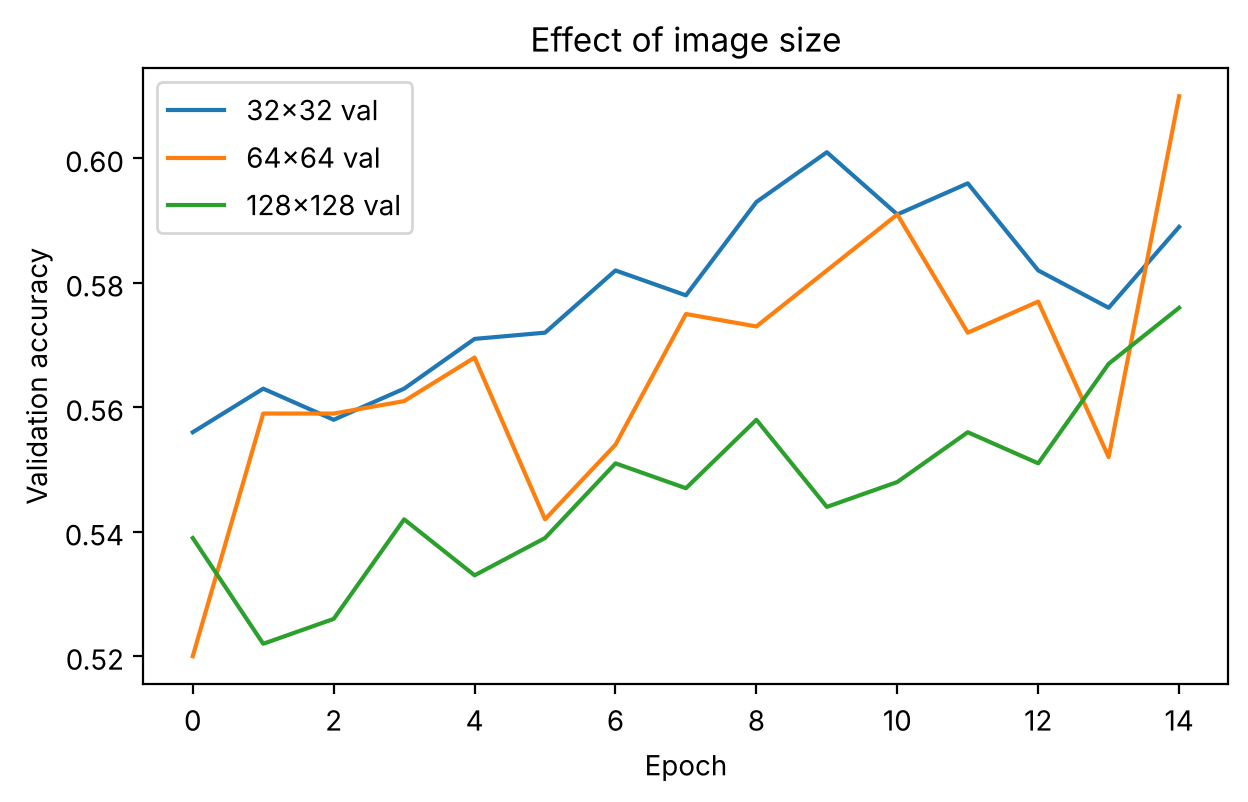

In [44]:
size_rows, size_hist = {}, {}
for s in [(32, 32), (64, 64), (128, 128)]:
    hist, r = train_catdog(size=s)
    size_rows[f"{s[0]}x{s[1]}"] = r; size_hist[s] = hist
    print(f"{s}: train={r['Train acc']:.4f} val={r['Val acc']:.4f} time={r['Time (s)']:.1f}s params={r['Params']:,}")

size_table = pd.DataFrame(size_rows).T
display(size_table.style.format({"Params": "{:,.0f}", "Time (s)": "{:.1f}", "Train acc": "{:.4f}", "Val acc": "{:.4f}",
                                 "Best val acc": "{:.4f}", "Gap (train-val)": "{:.4f}",
                                 "Final train loss": "{:.4f}", "Final val loss": "{:.4f}"}))

plt.figure(figsize=(7, 4))
for s, hist in size_hist.items():
    plt.plot(hist.history["val_accuracy"], label=f"{s[0]}x{s[1]} val")
plt.xlabel("Epoch"); plt.ylabel("Validation accuracy"); plt.legend(); plt.title("Effect of image size")
plt.show()

**Answer:**

| Image size | Inputs | Params | Train acc | Val acc | Time (15 epochs) |
|---|---|---|---|---|---|
| 32x32 | 1,024 | 139,521 | 0.676 | 0.589 | 5.2 s |
| 64x64 | 4,096 | 532,737 | 0.650 | **0.610** | 7.9 s |
| 128x128 | 16,384 | 2,105,601 | 0.672 | 0.576 | 14.5 s |

**Training time** grows with image size. Each doubling of the side length gives 4x the pixels and roughly 4x the weights in the first dense layer. Time grows less than 4x because data loading and per-step overhead are a fixed cost.

**Accuracy does not improve** with bigger images. 64x64 is slightly best, and 128x128 is the worst. A bigger image gives the model millions more weights to learn from the same 2,000 photos, which makes it harder to train and easier to overfit. A dense layer also can't make use of the extra detail. All three results sit within the ±3 point noise seen between epochs, so the main conclusion is that **resolution is not the bottleneck for a dense ANN**. 32x32 is the cheapest for nearly the same result.

**4.4 Remove the Rescaling layer**

,Train acc,Val acc,Best val acc,Gap (train-val),Final train loss,Final val loss,Time (s)
With Rescaling(1/255),0.6500,0.61,0.61,0.0400,0.6232,0.6637,7.8600
Without Rescaling,0.6175,0.51,0.55,0.1075,0.7932,0.9633,7.5865


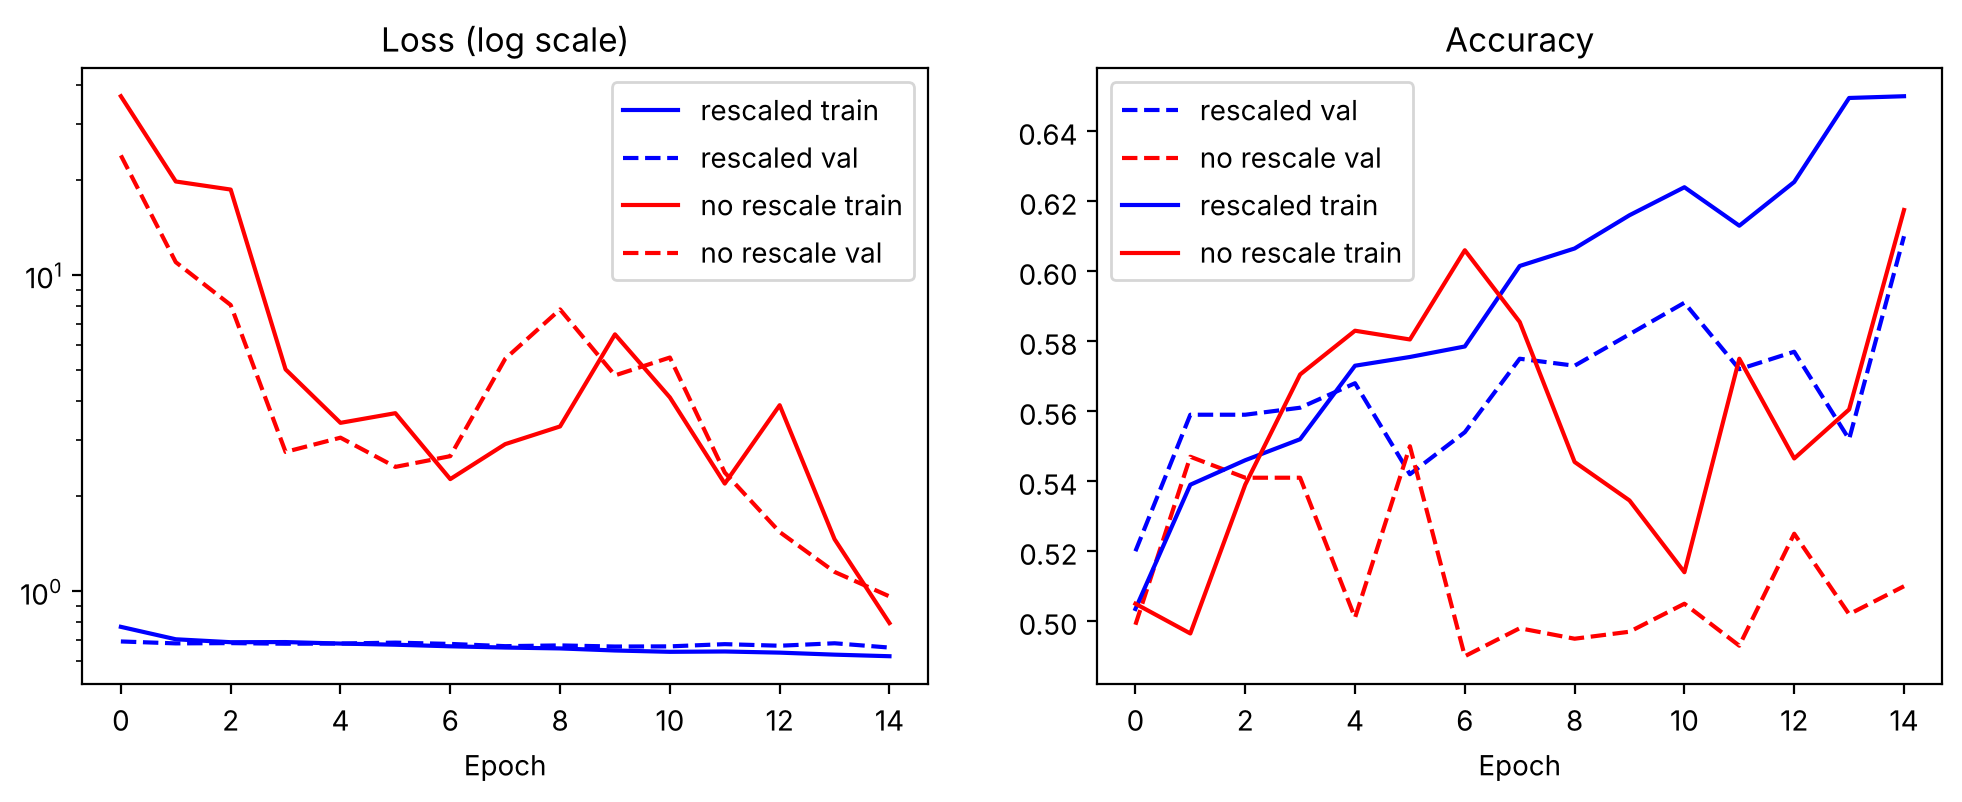

In [45]:
hist_norescale, r_norescale = train_catdog(size=(64, 64), rescale=False)
r_rescale = size_rows["64x64"]

rescale_table = pd.DataFrame({"With Rescaling(1/255)": r_rescale, "Without Rescaling": r_norescale}).T
display(rescale_table.drop(columns=["Params"]).round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(size_hist[(64, 64)].history["loss"], "b-", label="rescaled train")
ax[0].plot(size_hist[(64, 64)].history["val_loss"], "b--", label="rescaled val")
ax[0].plot(hist_norescale.history["loss"], "r-", label="no rescale train")
ax[0].plot(hist_norescale.history["val_loss"], "r--", label="no rescale val")
ax[0].set_yscale("log"); ax[0].set_title("Loss (log scale)"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(size_hist[(64, 64)].history["val_accuracy"], "b--", label="rescaled val")
ax[1].plot(hist_norescale.history["val_accuracy"], "r--", label="no rescale val")
ax[1].plot(size_hist[(64, 64)].history["accuracy"], "b-", label="rescaled train")
ax[1].plot(hist_norescale.history["accuracy"], "r-", label="no rescale train")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.show()

**Answer:**

Without `Rescaling`, the model **barely learns**. Final validation accuracy is **0.51** (best 0.55), which is basically chance, compared with 0.61 when rescaled. The final validation loss is **0.963 vs 0.664**. On the log-scale plot, the unscaled loss starts more than an order of magnitude higher and jumps around erratically. Training accuracy (0.6175) is also well above validation, a 0.11 gap, so whatever it learns does not generalise.

**Why:** with 4,096 inputs of up to 255 each, the first layer's weighted sums are enormous. The sigmoid output saturates at 0 or 1, giving extremely confident predictions. When those are wrong, binary cross-entropy explodes, and the huge, unstable gradients make every Adam step overshoot. This is the same effect as in Task 3.2, only much stronger, because there are more inputs and far less data.

**4.5 Data augmentation (RandomFlip + RandomRotation) before Rescaling**

,Train acc,Val acc,Best val acc,Gap (train-val),Final train loss,Final val loss,Time (s)
No augmentation,0.650,0.610,0.610,0.040,0.6232,0.6637,7.8600
With augmentation,0.575,0.568,0.582,0.007,0.6682,0.6603,11.5152


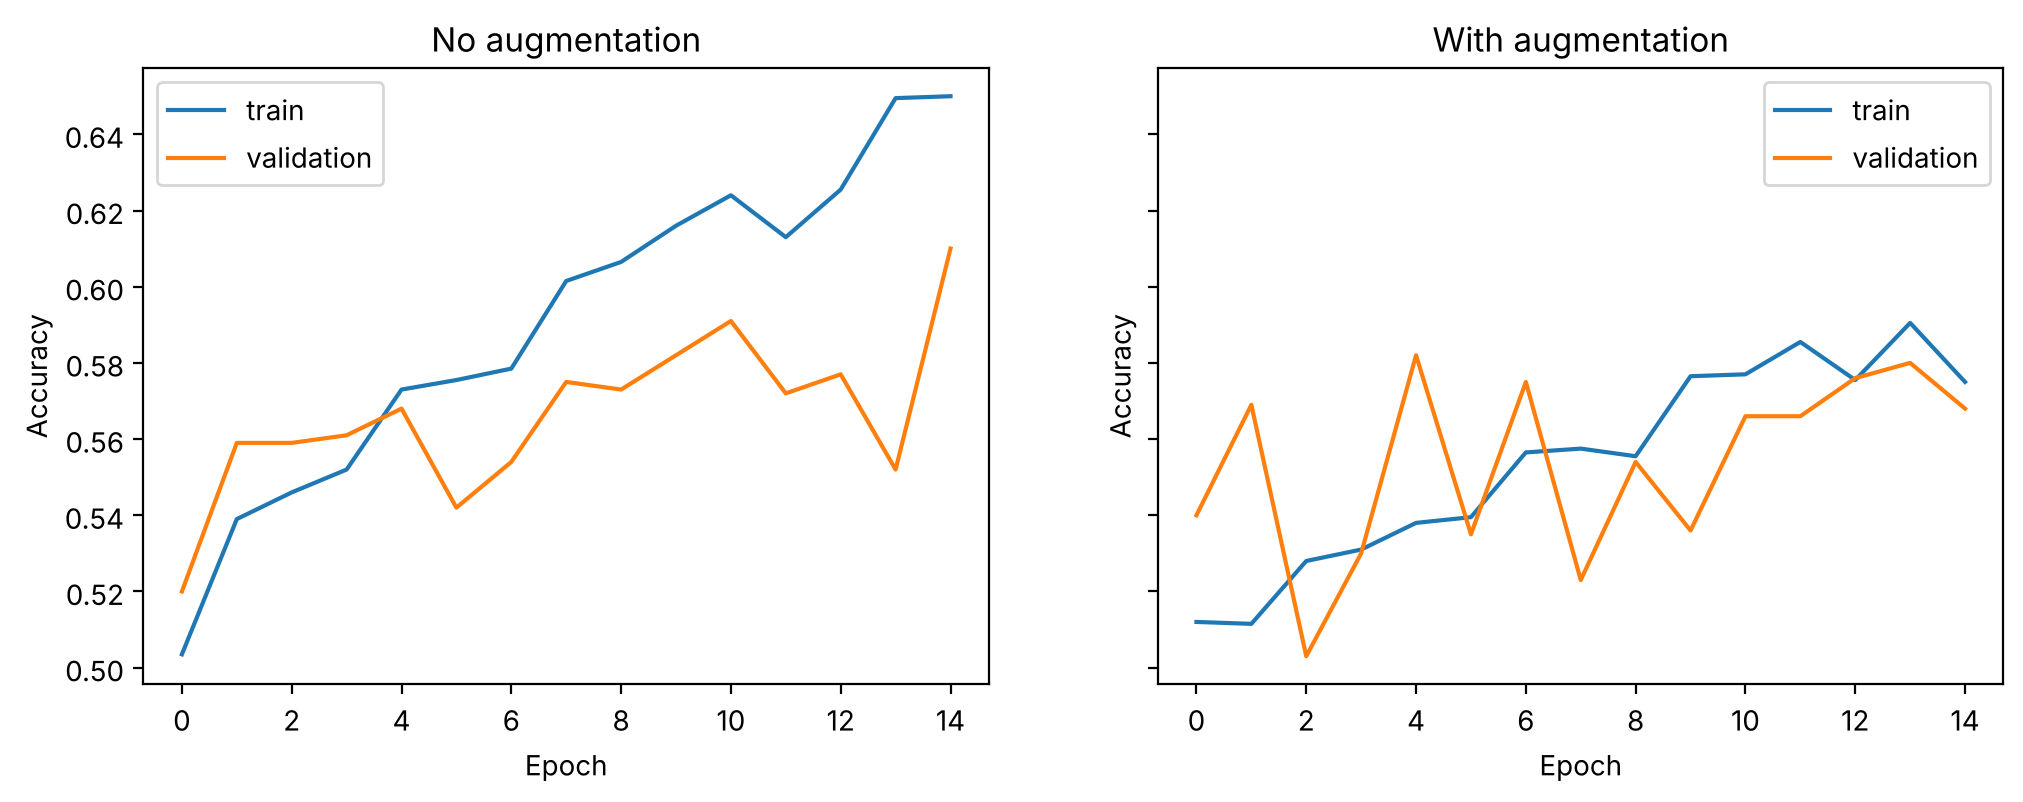

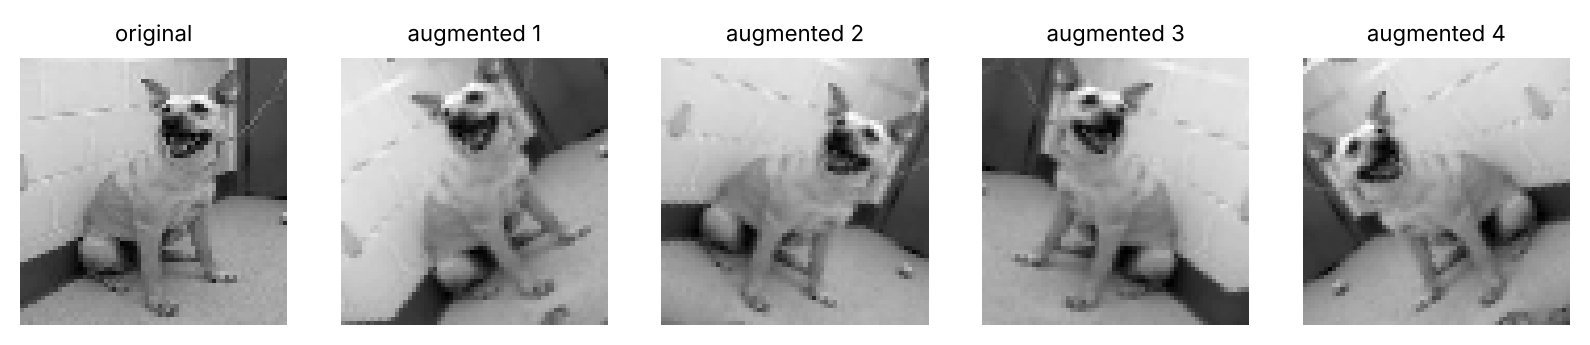

In [46]:
hist_aug, r_aug = train_catdog(size=(64, 64), augment=True)

aug_table = pd.DataFrame({"No augmentation": r_rescale, "With augmentation": r_aug}).T
display(aug_table.drop(columns=["Params"]).round(4))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (title, hist) in zip(ax, [("No augmentation", size_hist[(64, 64)]), ("With augmentation", hist_aug)]):
    a.plot(hist.history["accuracy"], label="train"); a.plot(hist.history["val_accuracy"], label="validation")
    a.set_title(title); a.set_xlabel("Epoch"); a.set_ylabel("Accuracy"); a.legend()
plt.show()

# What the augmentation layers produce
aug = tf.keras.Sequential([tf.keras.layers.RandomFlip("horizontal"), tf.keras.layers.RandomRotation(0.1)])
sample = next(iter(train_ds))[0][:1]
plt.figure(figsize=(10, 2.5))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    out = sample if i == 0 else aug(sample, training=True)
    plt.imshow(out[0].numpy().squeeze(), cmap="gray"); plt.axis("off")
    plt.title("original" if i == 0 else f"augmented {i}", fontsize=8)
plt.show()

**Answer:**

| | Train acc | Val acc | Gap (train - val) | Time |
|---|---|---|---|---|
| No augmentation | 0.650 | **0.610** | 0.040 | 7.9 s |
| With augmentation | 0.575 | 0.568 | **0.007** | 11.5 s |

**Overfitting shrinks** (the gap goes from 0.040 to 0.007) because the model never sees exactly the same image twice: every epoch the images are randomly flipped and rotated. However, **validation accuracy dropped** (0.61 to 0.57). This model was already underfitting, and augmentation makes the training task harder. For a dense network it is especially hard: a flipped or rotated cat moves every pixel to a new input position, and the dense layer treats each position as an unrelated feature. Augmentation pays off much more with convolutional networks, which are designed to handle shifted patterns.

**4.6 Discussion: why does flattening hurt, and what layer handles images better?**

**Answer:**

Our dense ANN reached about **60%**, right in the expected 55 to 65% range.

**Why flattening hurts:** `Flatten` turns the 64x64 image into 4,096 independent numbers and throws away the spatial structure. The network no longer knows which pixels are neighbours. An eye, ear or snout must be learned separately at every possible position, and a cat shifted by 10 pixels is a completely different input vector. Cats and dogs appear in different positions, sizes, poses and backgrounds. With only 2,000 images and over 500k weights, the dense network can pick up only crude global patterns such as overall brightness and contrast. Converting to grayscale also removes colour cues.

**Better layer: convolutional layers (`Conv2D` + `MaxPooling2D`).** A convolution slides small filters with shared weights across the image. This keeps the 2D structure and detects local features that build up layer by layer (edges, then textures, then parts like eyes and ears). Weight sharing means far fewer parameters, and with pooling the network becomes tolerant to where the object sits in the frame. A small CNN with augmentation typically reaches about 70 to 80% on this dataset, and transfer learning from a pretrained CNN (e.g. MobileNetV2) goes above 95%.

## Summary

* **Normalization** (min-max or z-score) puts features on a common scale. Its statistics must come from the training set only.
* **Image preprocessing:** fixed-size resizing, grayscale conversion and `/255` scaling. The exact same steps must be applied at prediction time.
* **Fashion-MNIST ANN (128-64):** train 0.9154, validation 0.8746, **test 0.8701**. Without normalization the test accuracy fell to 0.8444, and the loss was 5 times higher in the first epoch.
* **Architecture:** width mattered more than depth (32 neurons: 85.8%, 256 neurons: 87.6%). 20 epochs overfit (train/val gap 0.066), and Dropout(0.2) cut the gap from 0.035 to 0.009.
* **Hardest classes:** T-shirt vs Shirt and Pullover vs Coat, because they have similar silhouettes at 28x28.
* **Keras `Normalization` / `Rescaling` layers** keep preprocessing inside the model so it can't be forgotten.
* **Cats vs dogs ANN:** about 60% validation accuracy. Removing `Rescaling` dropped it to chance level, augmentation removed the train/val gap, and bigger images didn't help. Dense layers are the limit here, and CNNs are the right tool for images.